# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-02-05"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p17"
subproj <- "AVGUSTINOVA_29_30"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

NULL

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

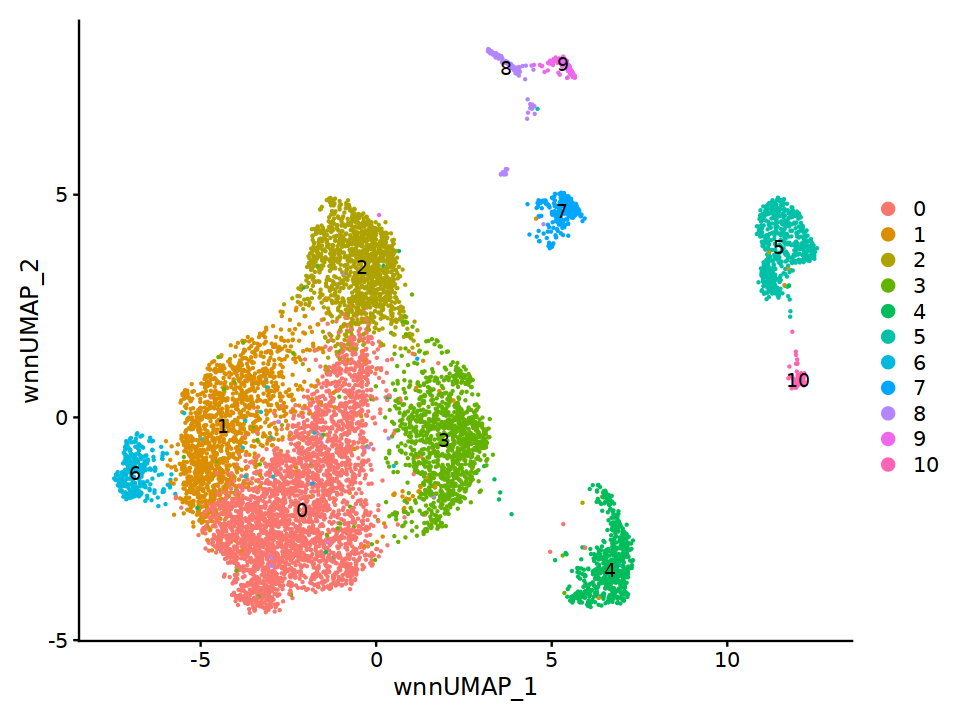

In [10]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

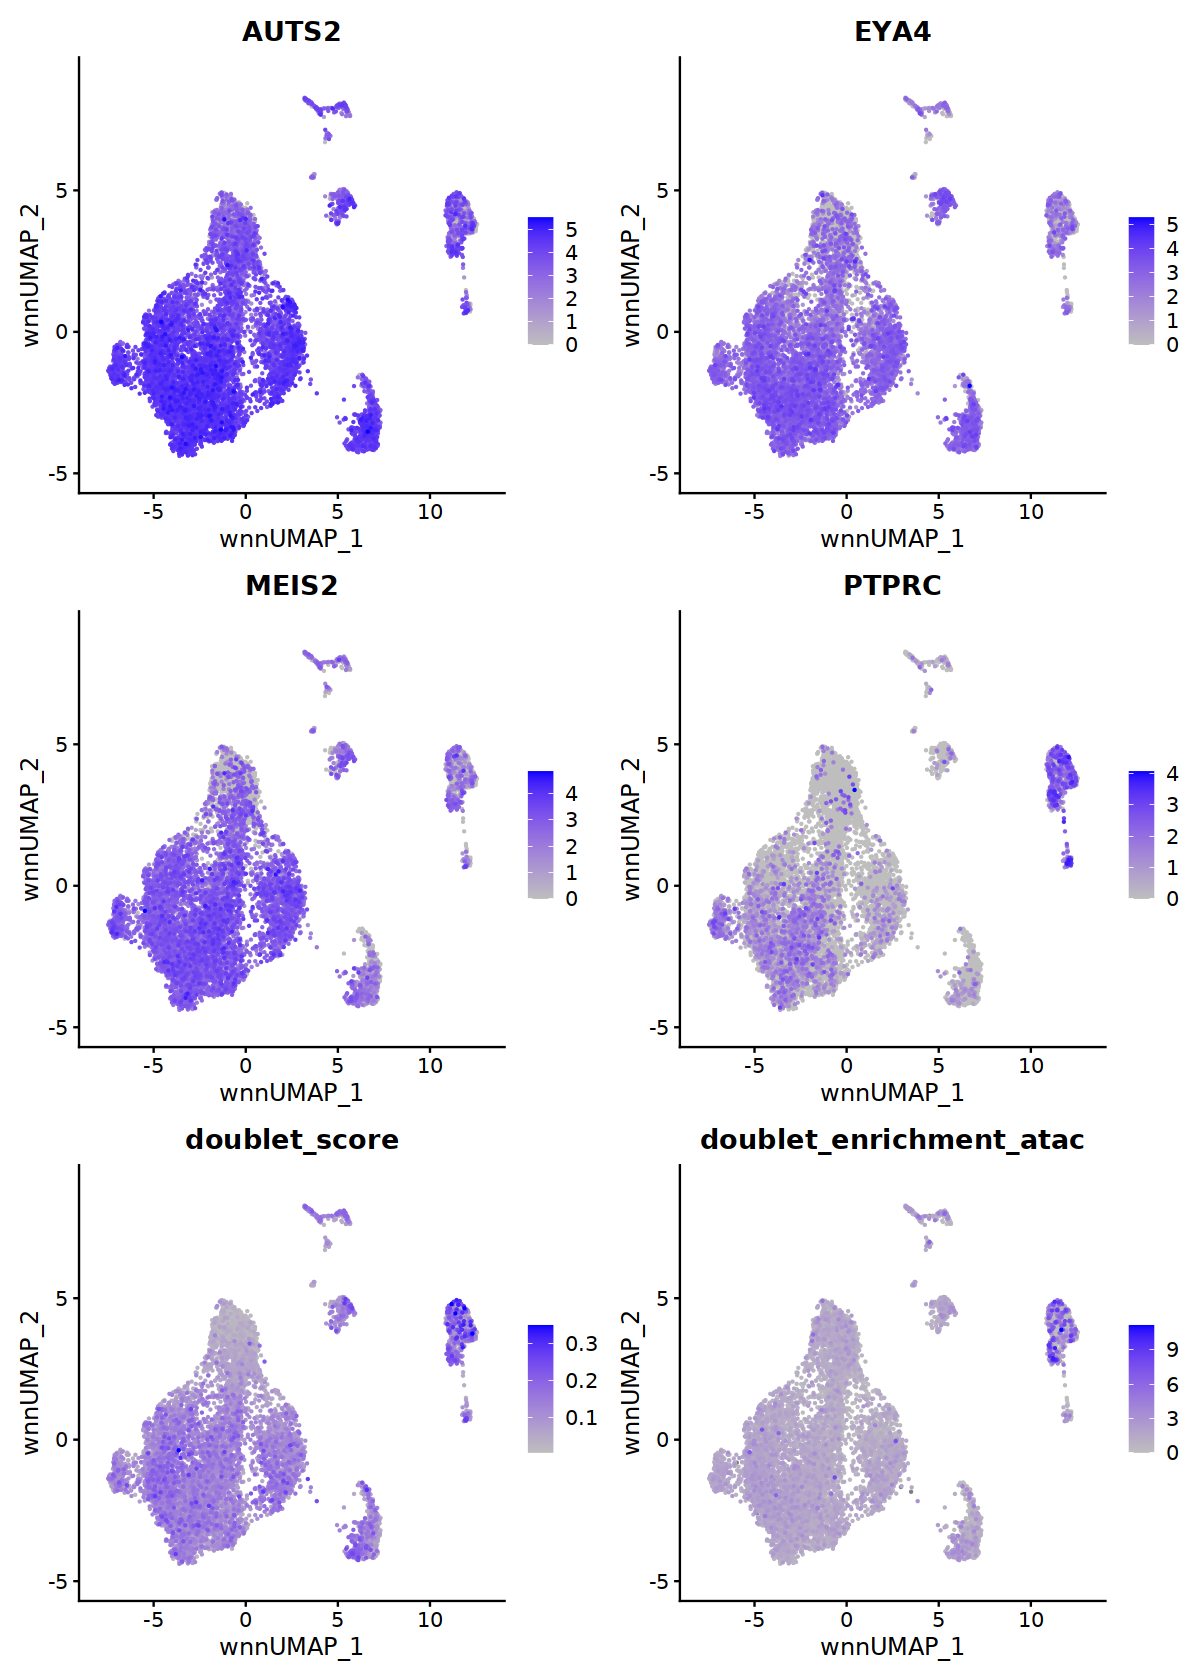

In [11]:
options(repr.plot.width = 10, repr.plot.height = 14)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("AUTS2","EYA4", "MEIS2", "PTPRC", "doublet_score", "doublet_enrichment_atac", ""),ncol=2,
            cols = c("gray", "blue"),  order=T)

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

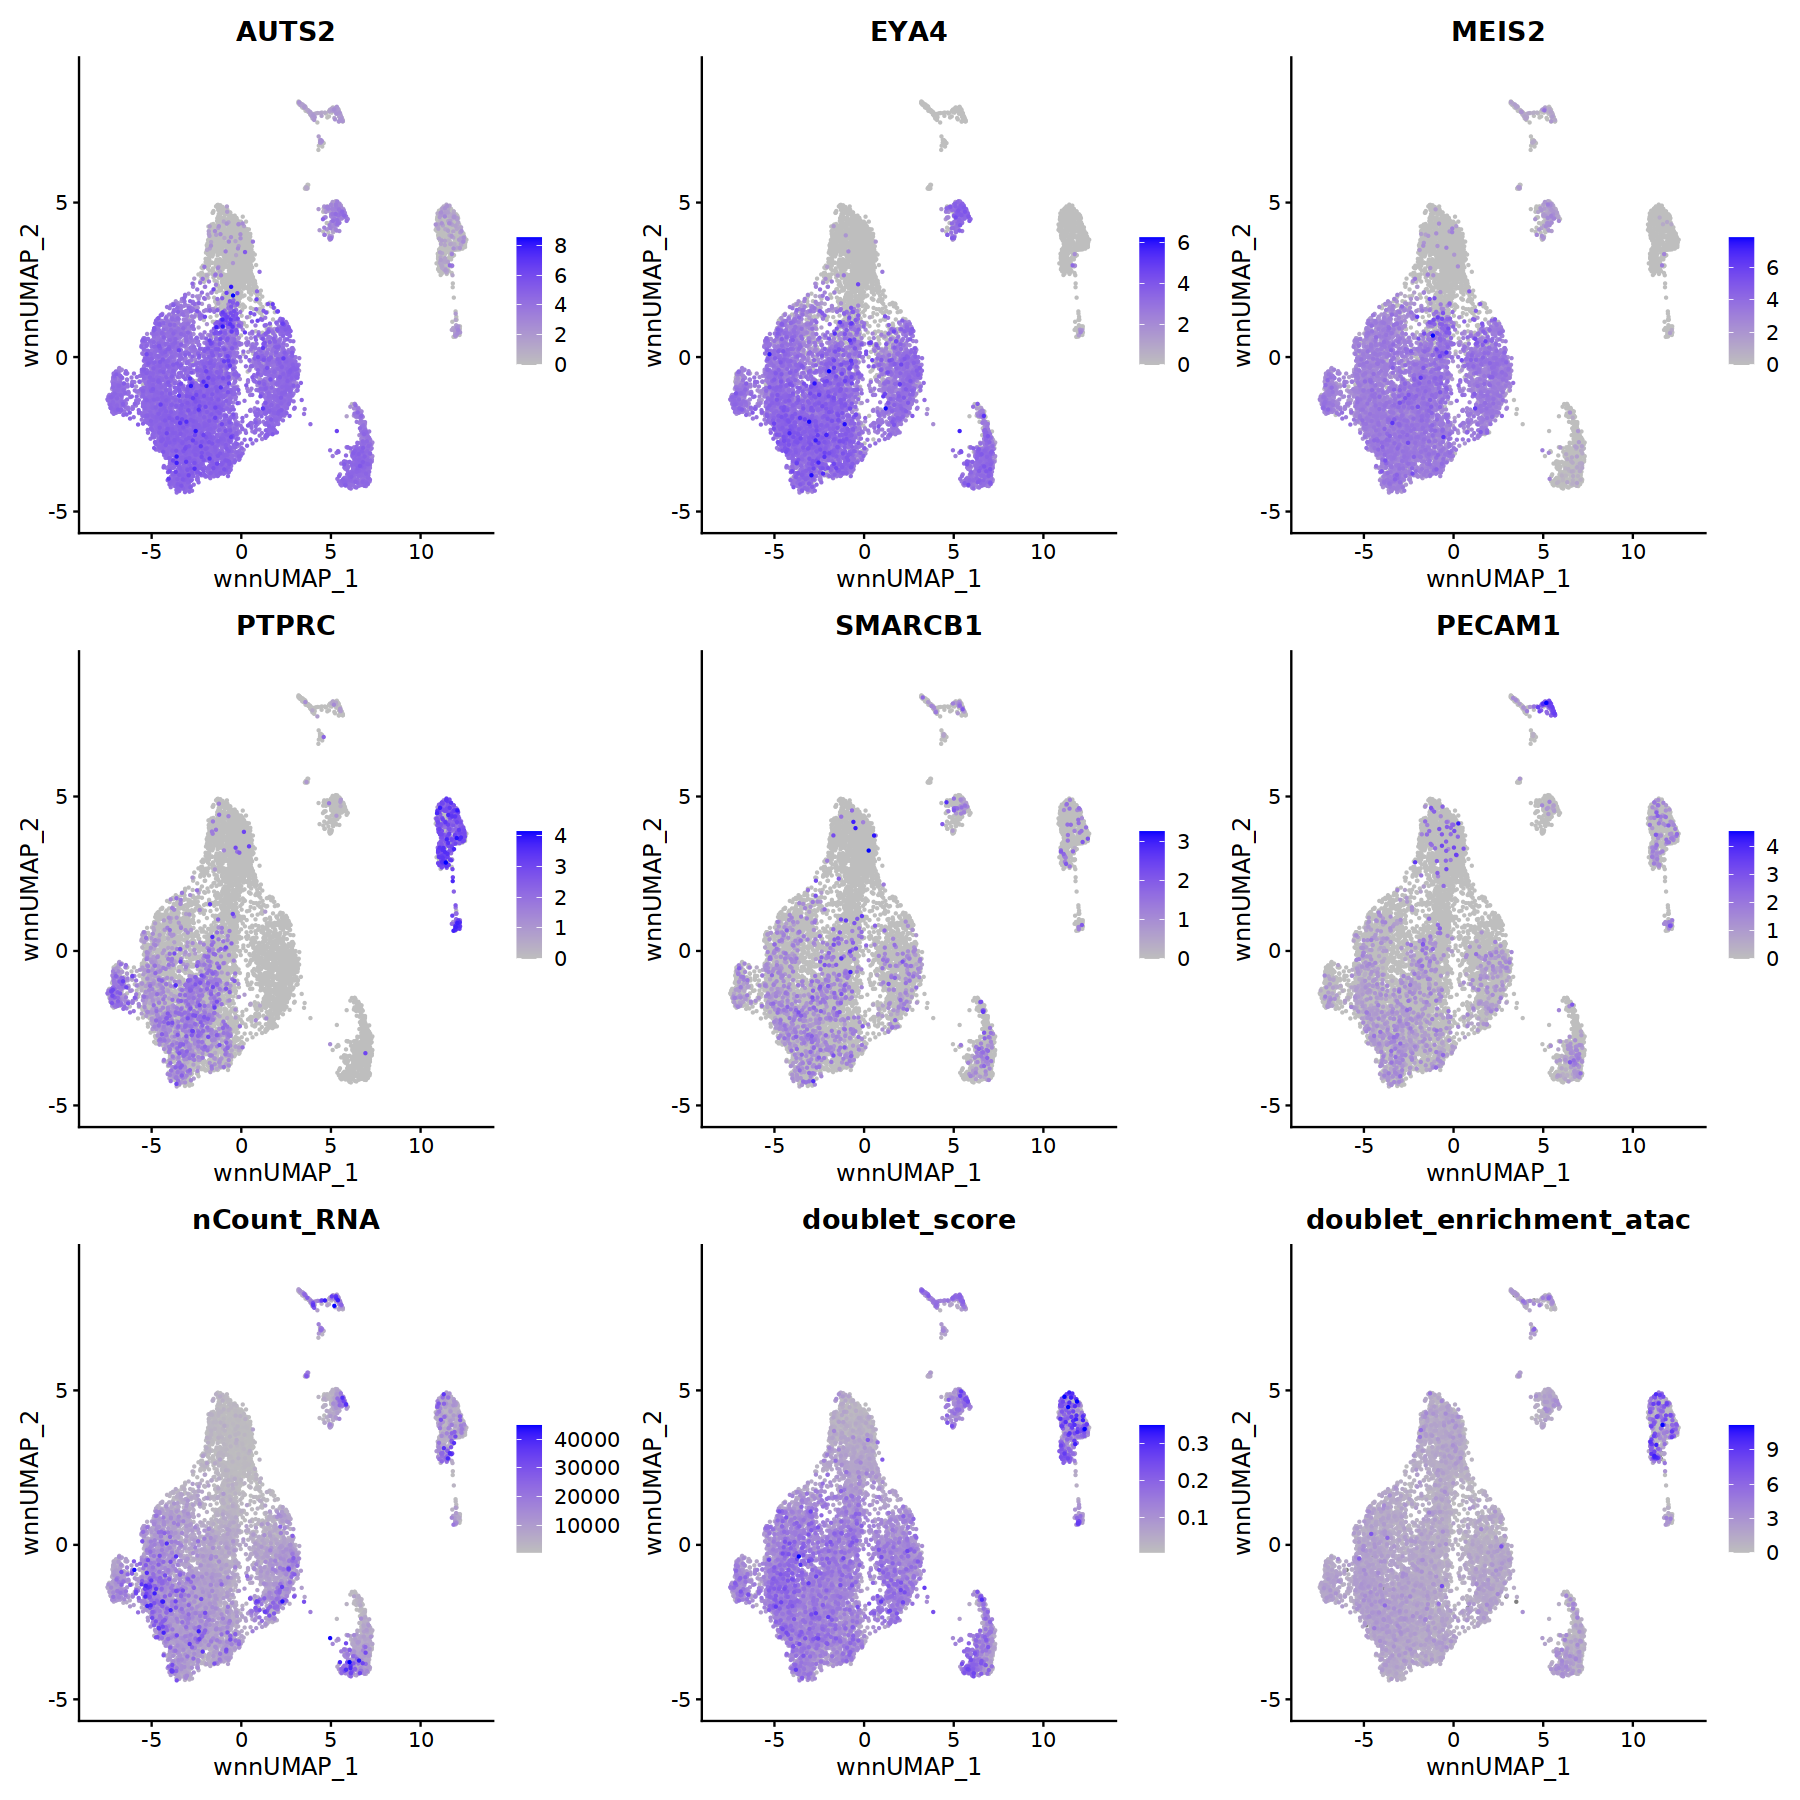

In [15]:
options(repr.plot.width = 15, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("AUTS2","EYA4", "MEIS2", "PTPRC","SMARCB1","PECAM1", 
                      "nCount_RNA", "doublet_score", "doublet_enrichment_atac"),
            ncol=3,cols = c("gray", "blue"), order=T)

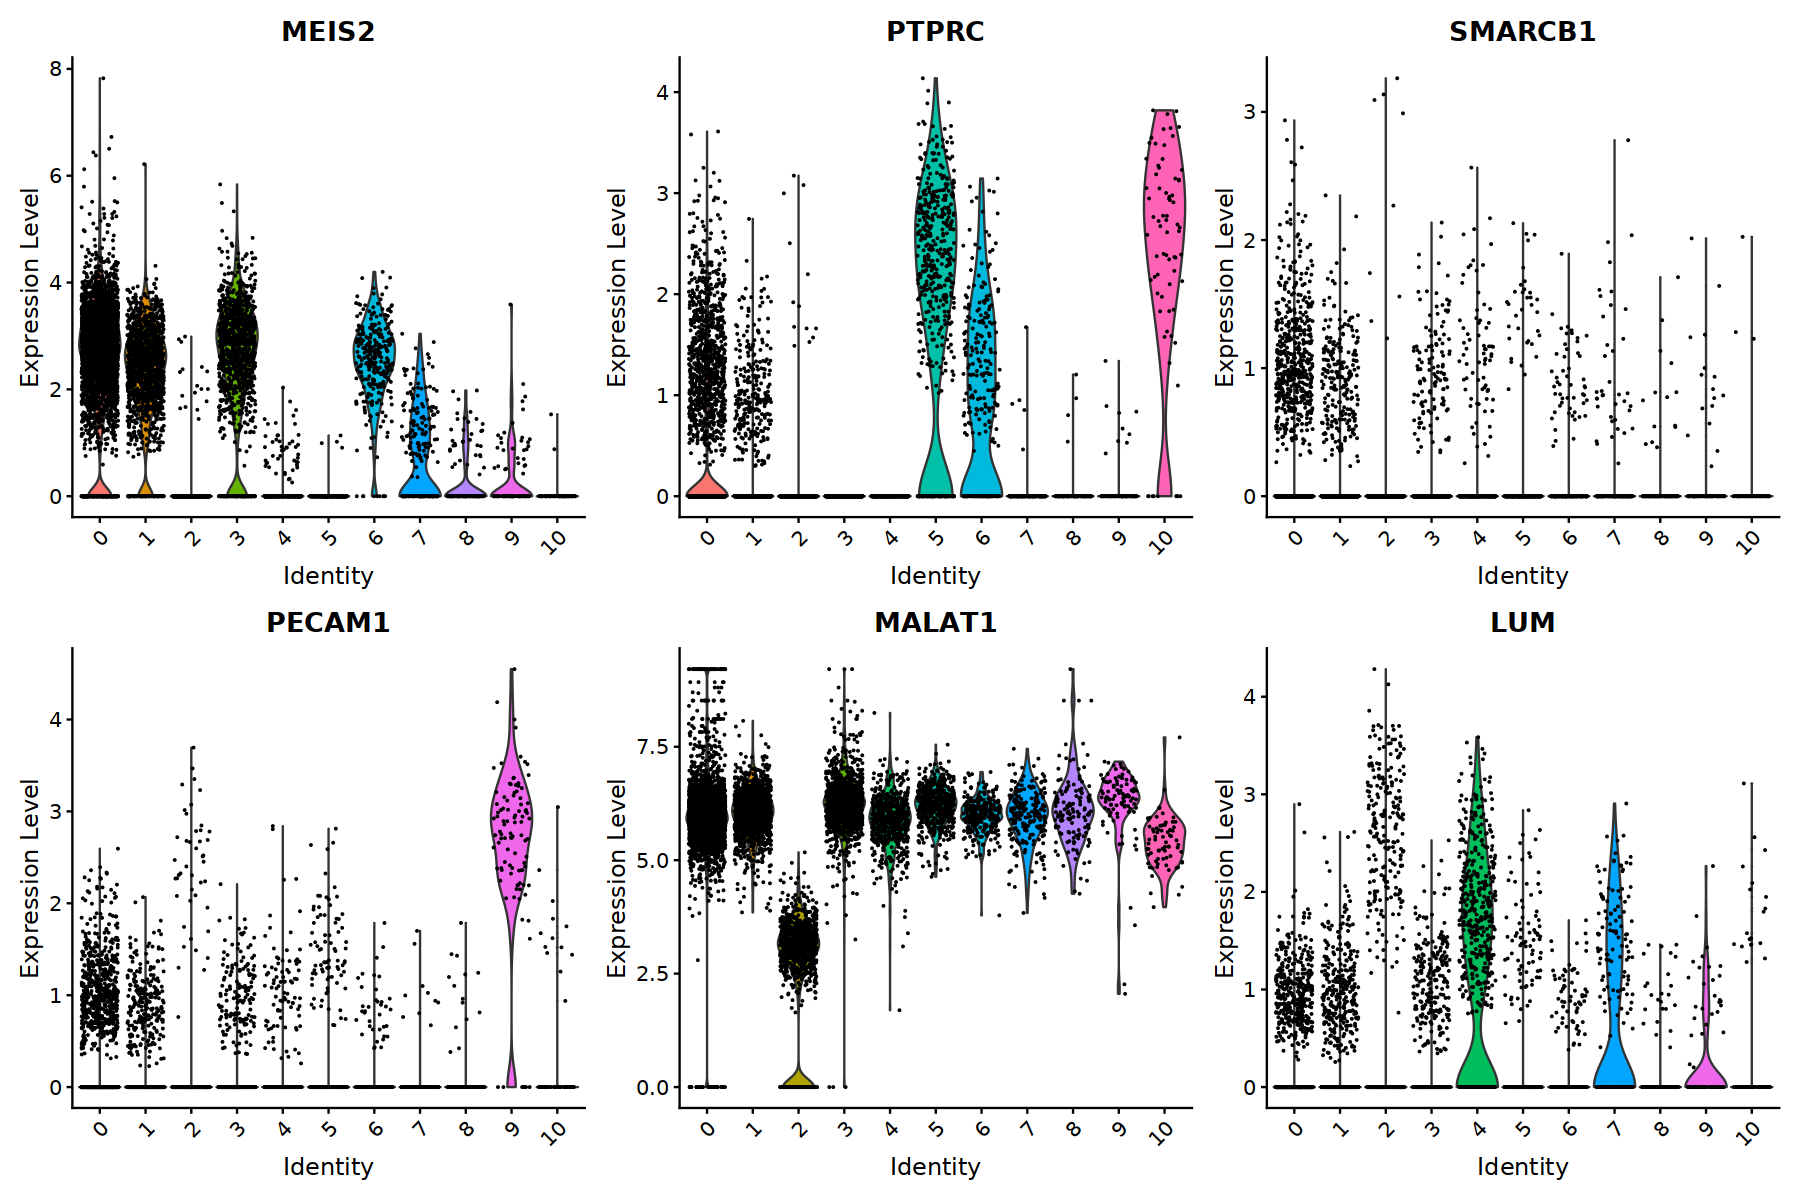

In [16]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj, features=c("MEIS2", "PTPRC","SMARCB1","PECAM1", "MALAT1", "LUM"),
        ncol=3)

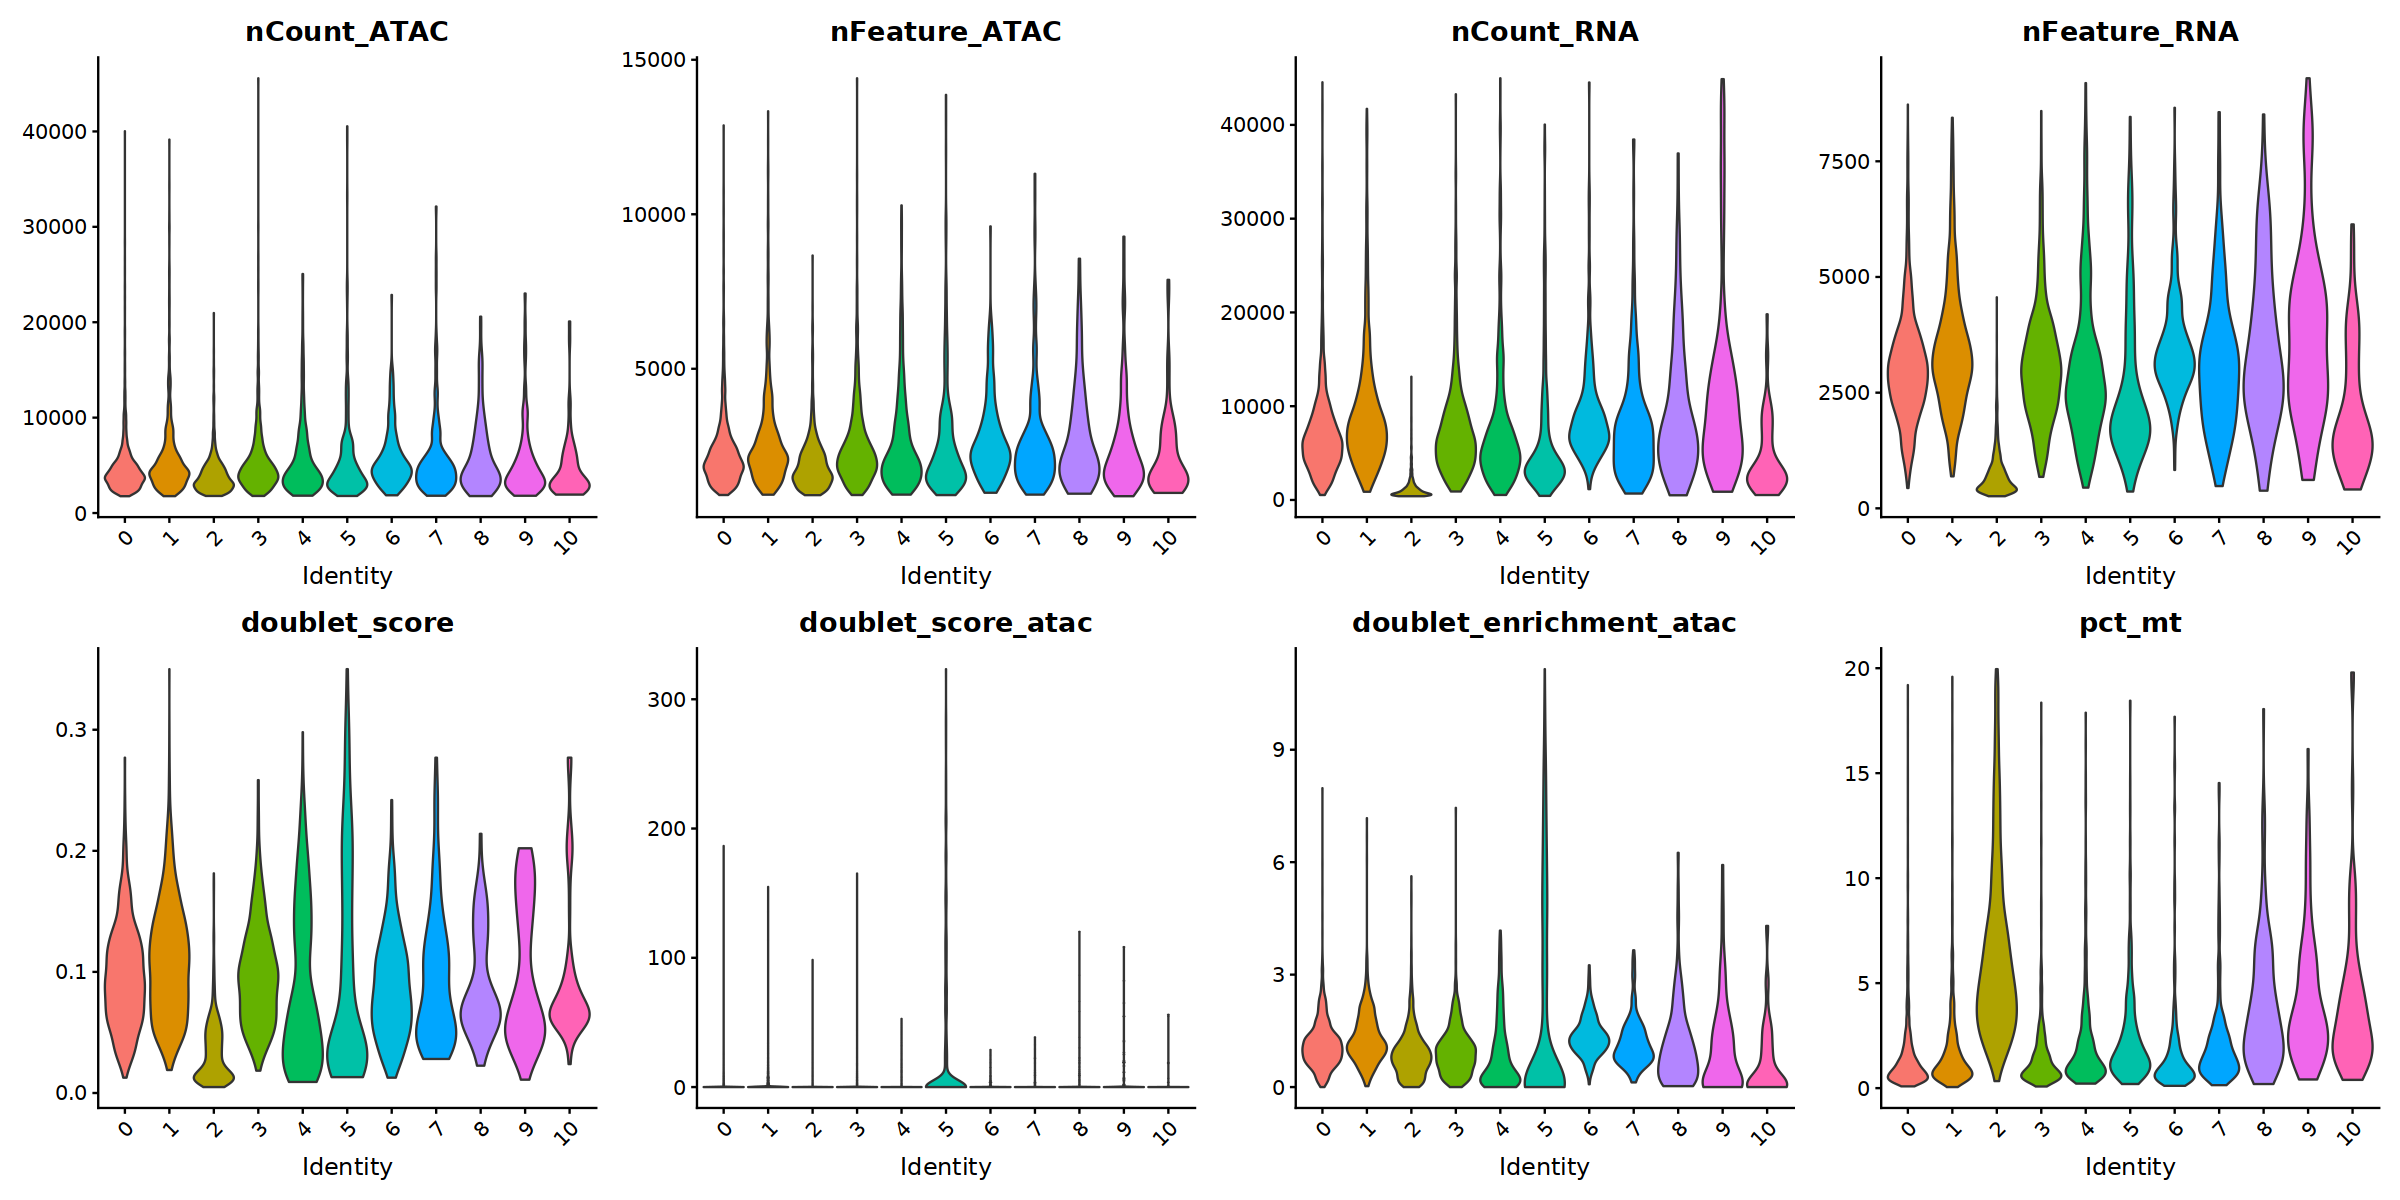

In [17]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj,features=c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt"), ncol=4, pt.size=0)

Remove tumor cells expressing CD45

In [18]:
df_tmp <- FetchData(seurat_obj, vars = c("PTPRC", "SMARCB1","PECAM1"), ident=c(0,1,3,6))

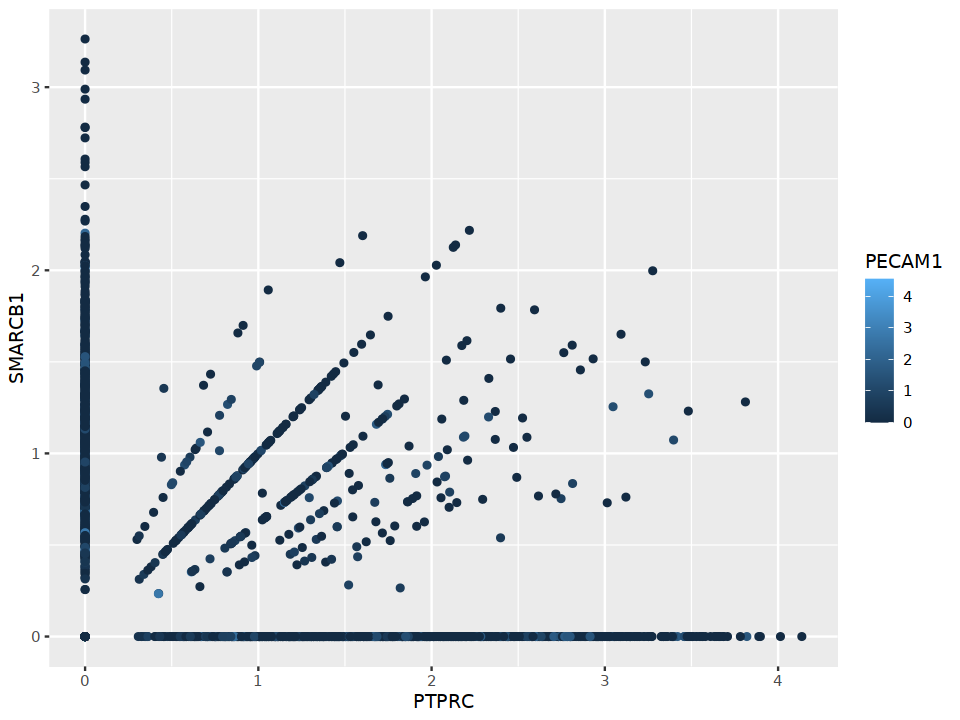

In [19]:
options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(df_tmp, aes(x = PTPRC, y = SMARCB1,color=PECAM1)) +
    geom_point()

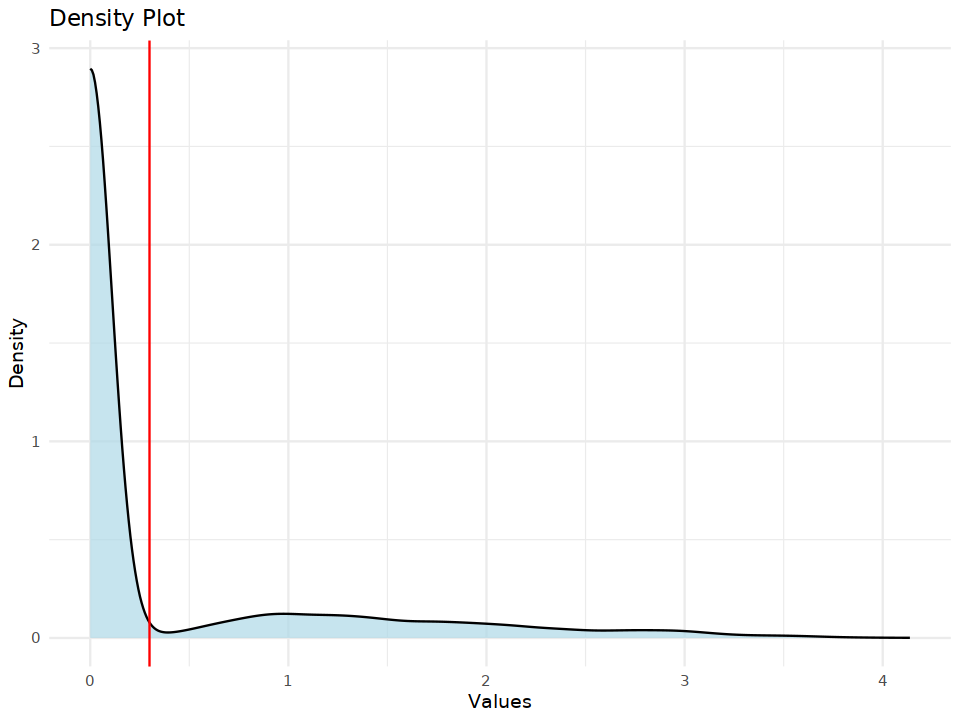

In [20]:
options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(df_tmp, aes(x = PTPRC)) +
  geom_density(fill = "lightblue", color = "black", alpha = 0.7) +
  labs(
    title = "Density Plot",
    x = "Values",
    y = "Density"
  ) +
  geom_vline(xintercept =0.3, color="red") +
  theme_minimal()

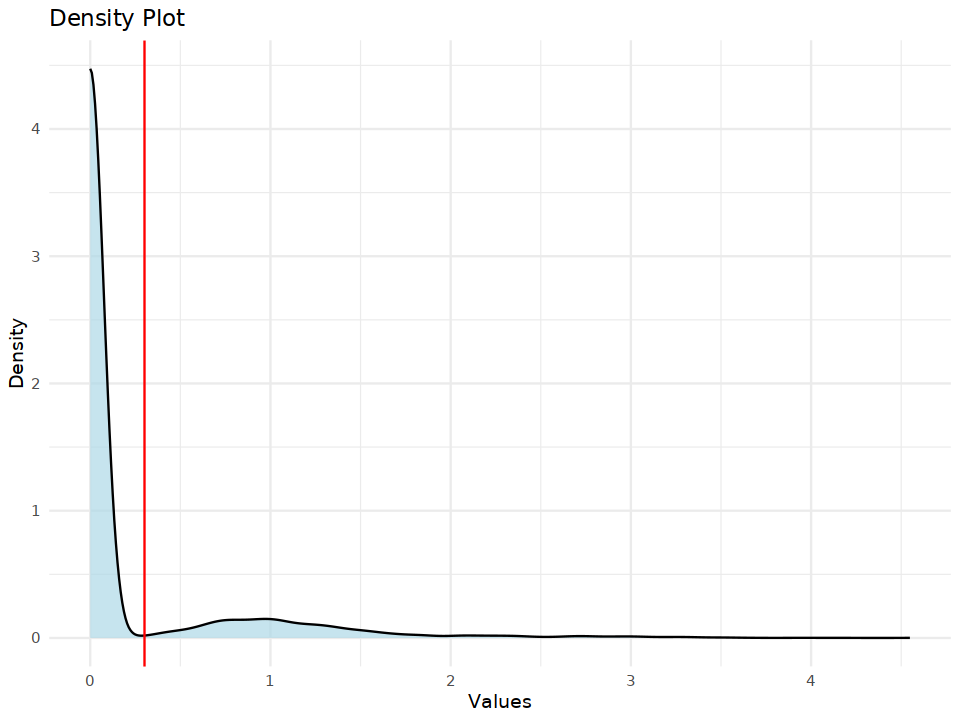

In [21]:
options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(df_tmp, aes(x = PECAM1)) +
  geom_density(fill = "lightblue", color = "black", alpha = 0.7) +
  labs(
    title = "Density Plot",
    x = "Values",
    y = "Density"
  ) +
  geom_vline(xintercept =0.3, color="red") +
  theme_minimal()

In [22]:
# filter specific cells 
cell_idents <- Idents(seurat_obj)

gene_expression_1 <- GetAssayData(seurat_obj, assay = "RNA", slot = "data")["PTPRC", ]
gene_expression_2 <- GetAssayData(seurat_obj, assay = "RNA", slot = "data")["PECAM1", ]

cells_to_remove <- which(cell_idents %in% c(0,1,3,6) & (gene_expression_1 > 0.3 | gene_expression_2 > 0.3))

seurat_obj <- subset(seurat_obj, cells = setdiff(colnames(seurat_obj), names(cells_to_remove)))

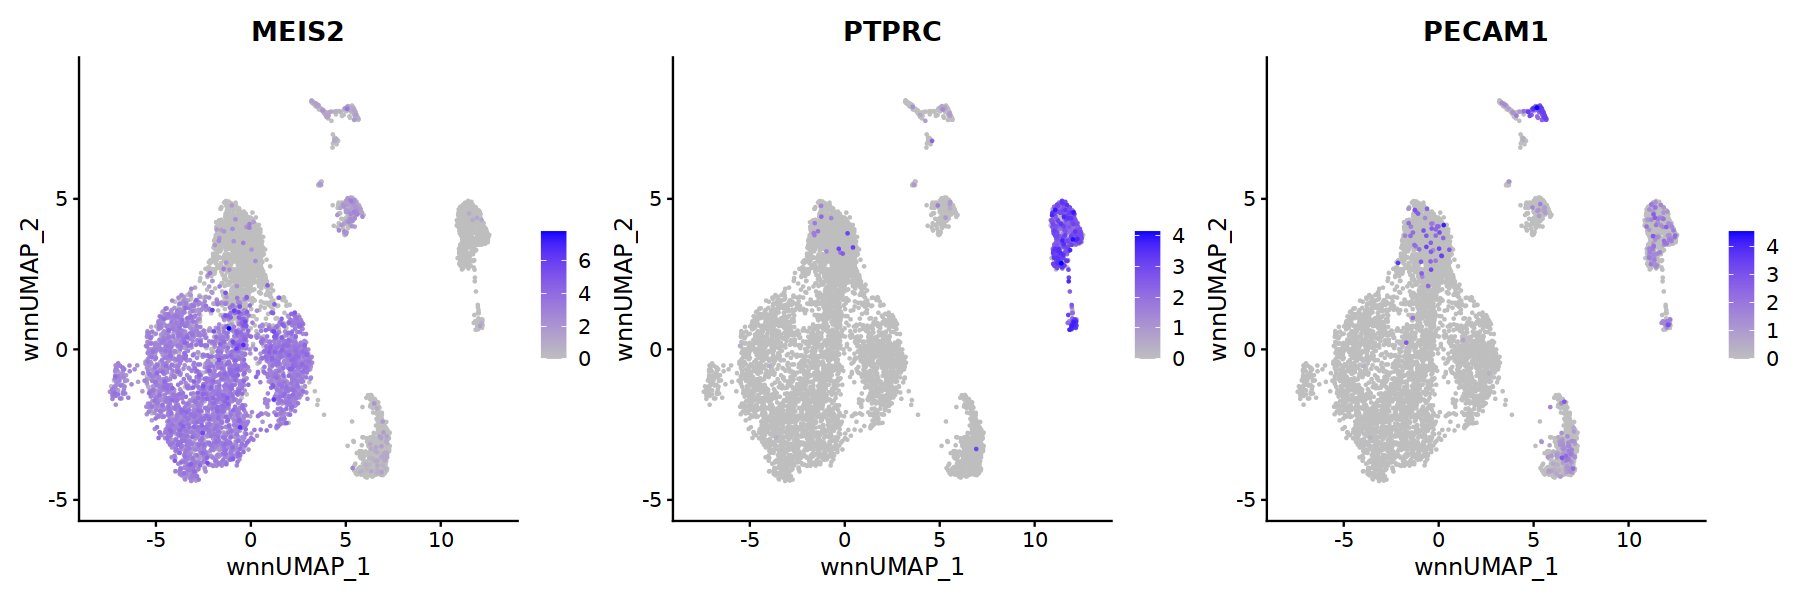

In [23]:
options(repr.plot.width = 15, repr.plot.height = 5)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MEIS2", "PTPRC", "PECAM1"),ncol=3,
            cols = c("gray", "blue"),  order=T)

Low quality cells 

In [24]:
markers <- FindMarkers(seurat_obj, ident.1 = "6", logfc.threshold=0.2, only.pos = T)
markers %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=20)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SORCS1,0.000000e+00,3.194316,0.696,0.006,0.000000e+00
SLC14A1,2.911175e-211,2.408925,0.759,0.036,9.357680e-207
PURPL,1.022191e-147,2.116390,0.709,0.046,3.285730e-143
B3GAT2,1.040168e-32,1.997650,0.734,0.219,3.343516e-28
PPFIBP1,7.775359e-41,1.979549,0.924,0.350,2.499312e-36
GNAL,8.287226e-36,1.901933,0.886,0.315,2.663846e-31
AC110023.1,3.322755e-73,1.901030,0.557,0.058,1.068067e-68
AC091078.1,4.077057e-75,1.713400,0.671,0.081,1.310529e-70
AL035446.2,2.989009e-137,1.700081,0.595,0.033,9.607871e-133


In [25]:
# apply filters
seurat_obj <- subset(seurat_obj, ident = 2, invert=T)

## Re-normalize

In [26]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [27]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [28]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [29]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

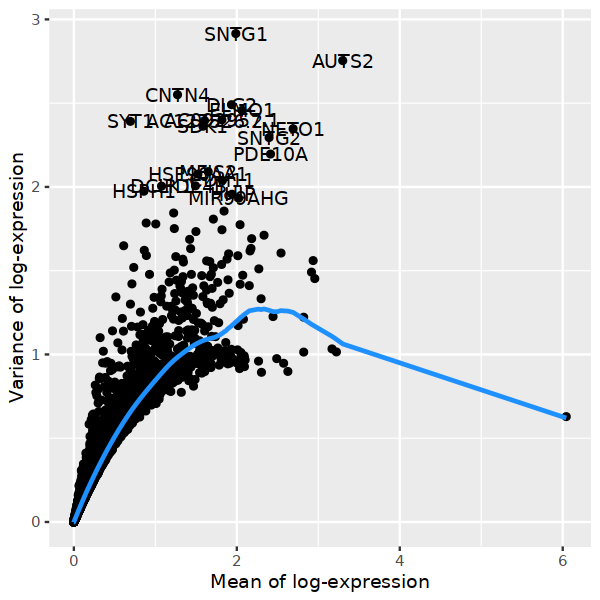

In [30]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [31]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 1961
[1] 1961


In [32]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  NETO1, AUTS2, SNTG2, PDE10A, EYA4, FANCC, MIR99AHG, FGFR2, HHIP, AC092957.1 
	   DLG2, CDH11, SNTG1, MEIS2, AC127526.2, ANGPT1, MIR3681HG, AL390957.1, SDK1, KCNN3 
	   TPO, AC011246.1, PRELID2, PPM1H, CACNA2D1, MKX, SMOC2, CNTN4, DCLK1, PXYLP1 
Negative:  DPYD, DOCK4, LRMDA, PLXDC2, ARHGAP26, FMNL2, ZEB2, MITF, ANKH, UTRN 
	   MAN1A1, ARHGAP18, LDLRAD4, FOXP1, DOCK8, LNCAROD, PTPRC, MSR1, TRPS1, SAT1 
	   ARHGAP15, MEF2C, FGD4, RAB31, VAV3, SRGN, SLC16A10, IQGAP2, CD163, KCNMA1 
PC_ 2 
Positive:  MITF, LNCAROD, RBM47, SLC16A10, KCNMA1, CD163, FMN1, PTPRC, DOCK8, CD86 
	   TBXAS1, AC100849.1, ADAM28, MS4A6A, NPL, CLEC7A, ANKH, ACSL1, TLR2, MRC1 
	   APBB1IP, MS4A7, SAMSN1, FAM20A, CCL4, SLA, AC131944.1, PTPRJ, PIK3R5, CCL3 
Negative:  COL4A2, COL4A1, IGFBP7, ADGRF5, PTPRK, CDH13, FILIP1, GRB10, PDE3A, CRIM1 
	   SORBS2, MCAM, SOX5, RAPGEF5, PALM2-AKAP2, ADAMTS9, MECOM, EPAS1, VWF, ADGRL4 
	   ANO2, GALNT18, CCN2, CAV1, LDB2, CCN1, APB

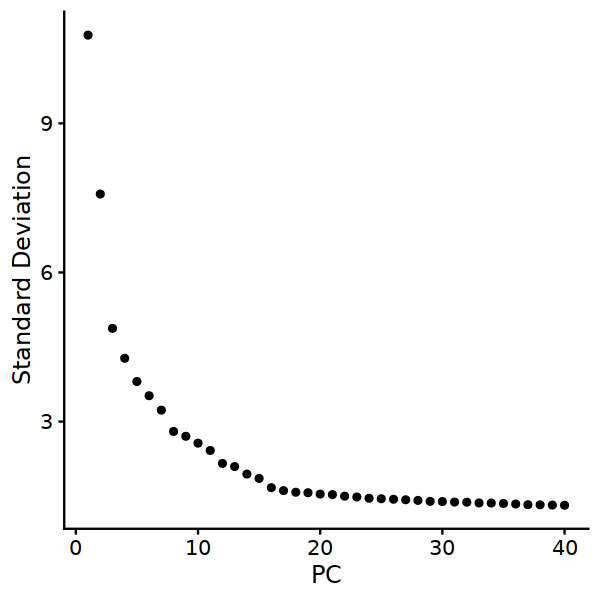

In [33]:
ElbowPlot(seurat_obj, n=40)

In [34]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
  assay.use = assay_ch
)

Suggested parameter: assay instead of assay.use


17:39:29 UMAP embedding parameters a = 0.9922 b = 1.112

17:39:29 Read 4865 rows and found 20 numeric columns

17:39:29 Using Annoy for neighbor search, n_neighbors = 30

17:39:29 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:39:30 Writing NN index file to temp file /scratch_tmp/53794293/RtmppKt9Vg/file1a50c19dd5cef

17:39:30 Searching Annoy index using 1 thread, search_k = 3000

17:39:31 Annoy recall = 99.22%

17:39:32 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:39:32 71 smooth knn distance failures

17:39:33 Initializing from normalized Laplacian + noise (using irlba)

17:39:34 Commencing optimization for 500 epochs, with 203404 positive edges

17:39:50 Optimization

In [35]:
seurat_obj

An object of class Seurat 
107756 features across 4865 samples within 3 assays 
Active assay: RNA_decontx (30863 features, 1961 variable features)
 2 other assays present: ATAC, RNA
 5 dimensional reductions calculated: pca, umap, lsi.atac, umap.atac, wnn.umap

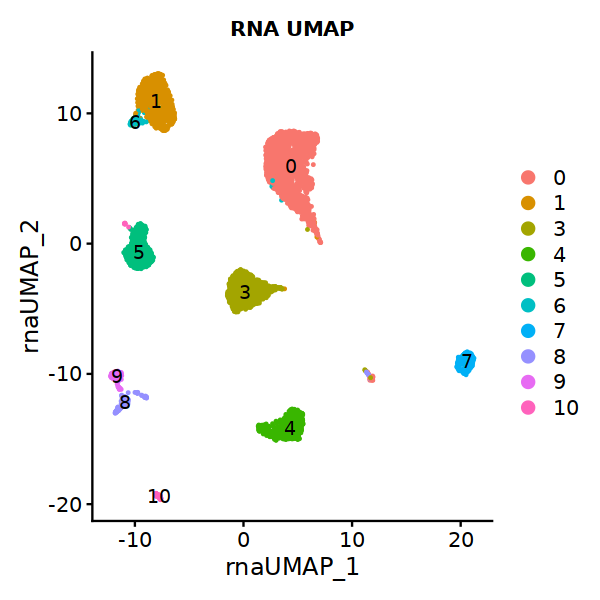

In [36]:
DimPlot(seurat_obj, reduction = "umap", label=T) + ggtitle(glue::glue('RNA UMAP')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

### ATAC

In [37]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [38]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



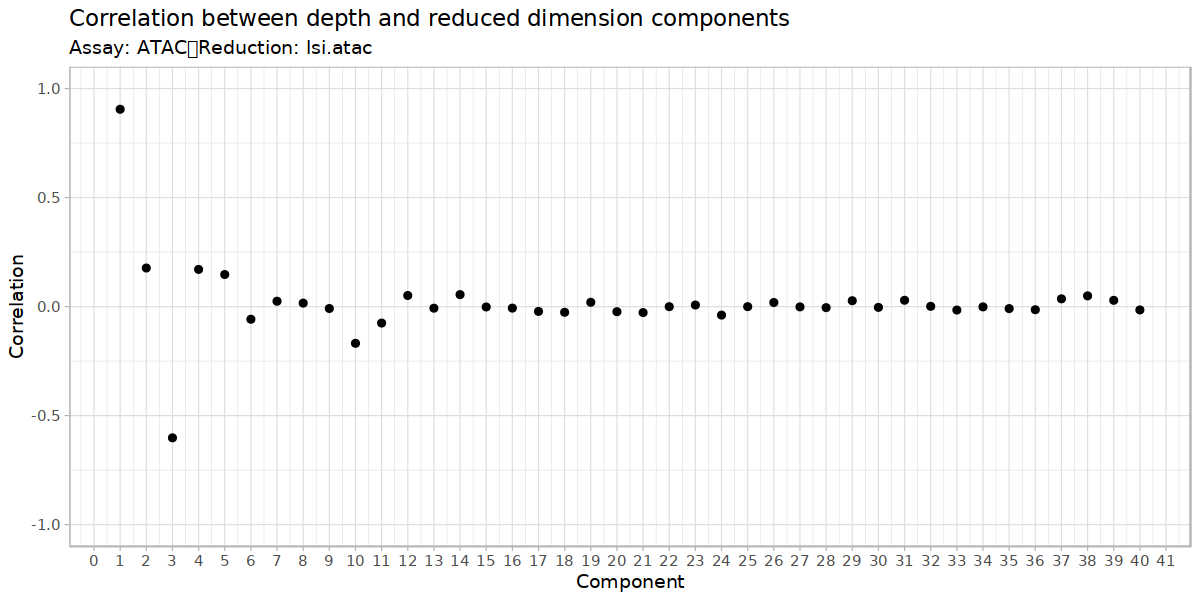

In [39]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

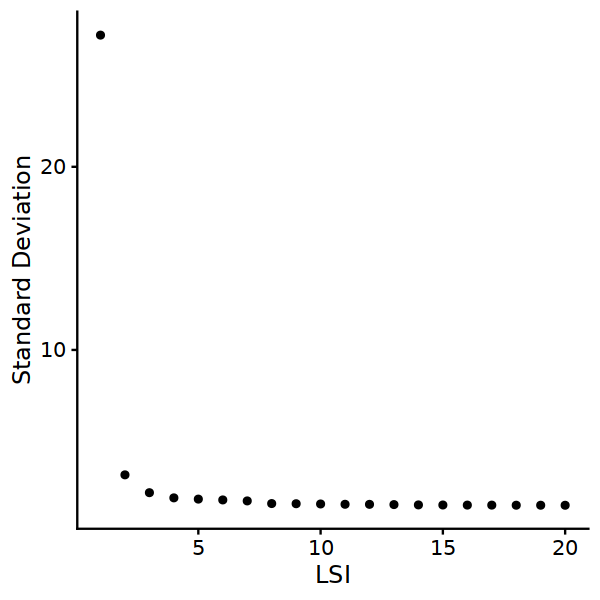

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [41]:
DefaultAssay(seurat_obj) <- assay_ch

In [42]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [43]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

17:40:12 UMAP embedding parameters a = 0.115 b = 1.929

17:40:13 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

17:40:13 55 smooth knn distance failures

17:40:14 Initializing from normalized Laplacian + noise (using irlba)

17:40:15 Commencing optimization for 500 epochs, with 146080 positive edges

17:40:31 Optimization finished



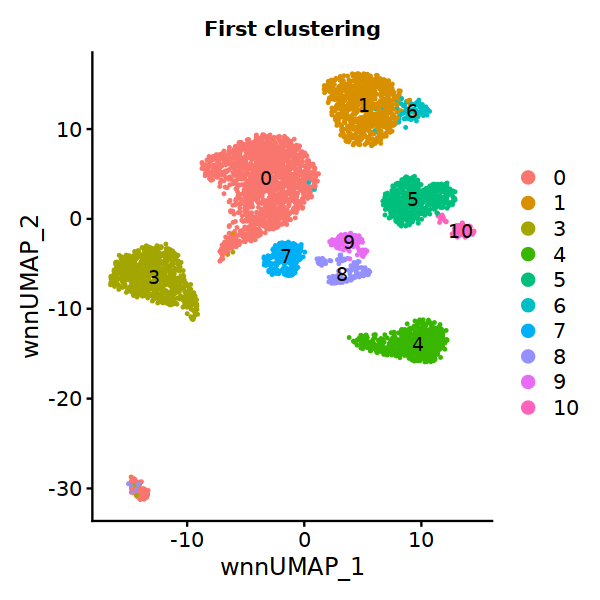

In [44]:
options(repr.plot.width = 5, repr.plot.height = 5)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T)+ ggtitle(glue::glue('First clustering')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))  

In [45]:
seurat_obj <- FindClusters(seurat_obj, resolution = 0.2,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4865
Number of edges: 198647

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9658
Number of communities: 9
Elapsed time: 0 seconds


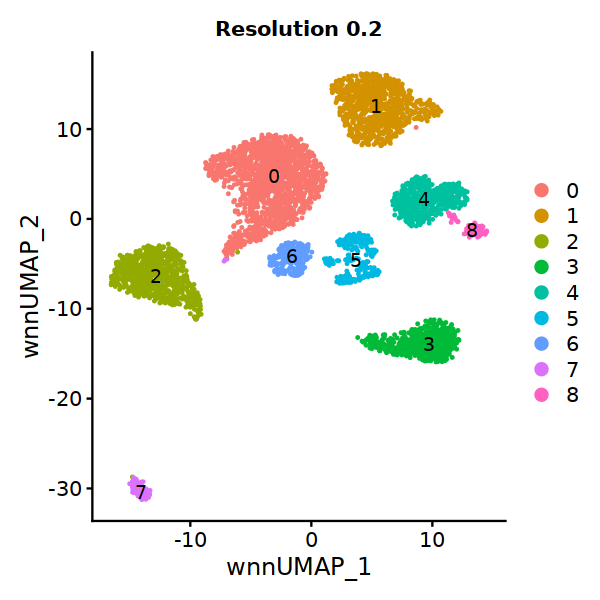

In [46]:
options(repr.plot.width = 5, repr.plot.height = 5)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T)+ ggtitle(glue::glue('Resolution 0.2')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))  

In [47]:
markers <- FindMarkers(seurat_obj, ident.1 = "7", logfc.threshold=0.2, only.pos = T)
markers %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=20)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MALAT1,4.671848e-16,3.5416330,0.747,1.000,1.441872e-11
DLGAP2,6.870000e-10,3.0298569,0.010,0.307,2.120288e-05
NEAT1,1.374288e-50,1.9100007,0.051,0.967,4.241464e-46
AC092957.1,5.487531e-26,1.8704917,0.030,0.654,1.693617e-21
AC127526.2,1.567981e-23,1.7437179,0.010,0.578,4.839261e-19
PITPNC1,4.972825e-34,1.6581543,0.020,0.741,1.534763e-29
VIM,4.404073e-08,1.2107743,0.010,0.258,1.359229e-03
PDE4D,7.915944e-12,1.0665364,0.020,0.374,2.443098e-07
AUTS2,1.745791e-42,1.0634943,0.040,0.876,5.388034e-38


In [48]:
# apply filters
seurat_obj <- subset(seurat_obj, ident = 7, invert=T)

## Re-process after more filtering

In [49]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [50]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [51]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [52]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

In [53]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 2208
[1] 2208


In [54]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  NETO1, AUTS2, SNTG2, PDE10A, HS3ST3A1, EYA4, FANCC, MIR99AHG, FGFR2, HHIP 
	   AC092957.1, CDH11, DLG2, SNTG1, MEIS2, AC127526.2, ANGPT1, MIR3681HG, AL390957.1, SDK1 
	   KCNN3, TPO, AC011246.1, PRELID2, PPM1H, CACNA2D1, SMOC2, MKX, CNTN4, DCLK1 
Negative:  DPYD, DOCK4, LRMDA, PLXDC2, ARHGAP26, FMNL2, ZEB2, MITF, ANKH, UTRN 
	   MAN1A1, ARHGAP18, LDLRAD4, FOXP1, DOCK8, PTPRC, LNCAROD, MSR1, TRPS1, SAT1 
	   ARHGAP15, MEF2C, FGD4, RAB31, VAV3, SRGN, IQGAP2, SLC16A10, CD163, KCNMA1 
PC_ 2 
Positive:  COL4A1, COL4A2, IGFBP7, ADGRF5, PTPRK, CDH13, FILIP1, GRB10, PDE3A, CRIM1 
	   SORBS2, MCAM, RAPGEF5, SOX5, ADAMTS9, PALM2-AKAP2, MECOM, PDLIM1, VWF, EPAS1 
	   ADGRL4, ANO2, GALNT18, CAV1, LDB2, PLVAP, CCN2, PTPRB, CCN1, RASGRF2 
Negative:  MITF, LNCAROD, RBM47, SLC16A10, KCNMA1, FMN1, CD163, PTPRC, DOCK8, TBXAS1 
	   CD86, AC100849.1, MS4A6A, ADAM28, NPL, CLEC7A, ANKH, ACSL1, TLR2, APBB1IP 
	   MRC1, MS4A7, SAMSN1, FAM20A, CCL4, SLA, PTP

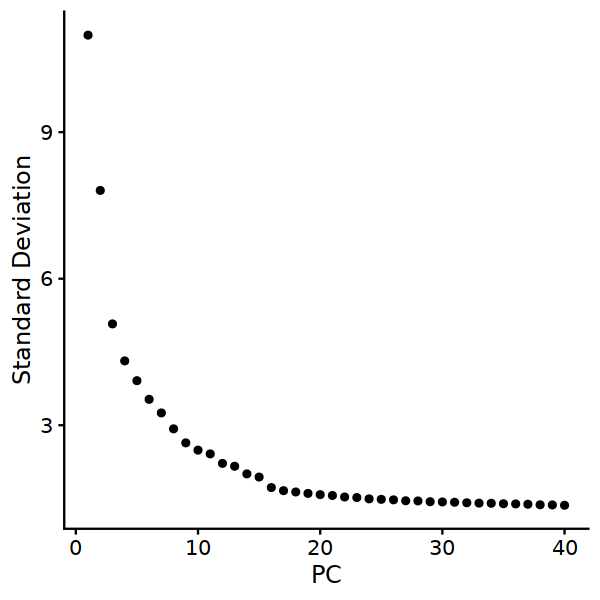

In [55]:
ElbowPlot(seurat_obj, n=40)

In [56]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
  assay.use = assay_ch
)

Suggested parameter: assay instead of assay.use


17:40:42 UMAP embedding parameters a = 0.9922 b = 1.112

17:40:42 Read 4766 rows and found 20 numeric columns

17:40:42 Using Annoy for neighbor search, n_neighbors = 30

17:40:42 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:40:43 Writing NN index file to temp file /scratch_tmp/53794293/RtmppKt9Vg/file1a50c53e00c2

17:40:43 Searching Annoy index using 1 thread, search_k = 3000

17:40:44 Annoy recall = 100%

17:40:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:40:46 Initializing from normalized Laplacian + noise (using irlba)

17:40:47 Commencing optimization for 500 epochs, with 197378 positive edges

17:41:01 Optimization finished



### ATAC

In [57]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [58]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



### Joint

In [59]:
DefaultAssay(seurat_obj) <- assay_ch

In [60]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [61]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

17:41:22 UMAP embedding parameters a = 0.115 b = 1.929

17:41:23 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

17:41:24 Initializing from normalized Laplacian + noise (using irlba)

17:41:24 Commencing optimization for 500 epochs, with 142344 positive edges

17:41:40 Optimization finished



In [62]:
seurat_obj <- FindClusters(seurat_obj, resolution = 0.2,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4766
Number of edges: 192930

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9624
Number of communities: 8
Elapsed time: 0 seconds


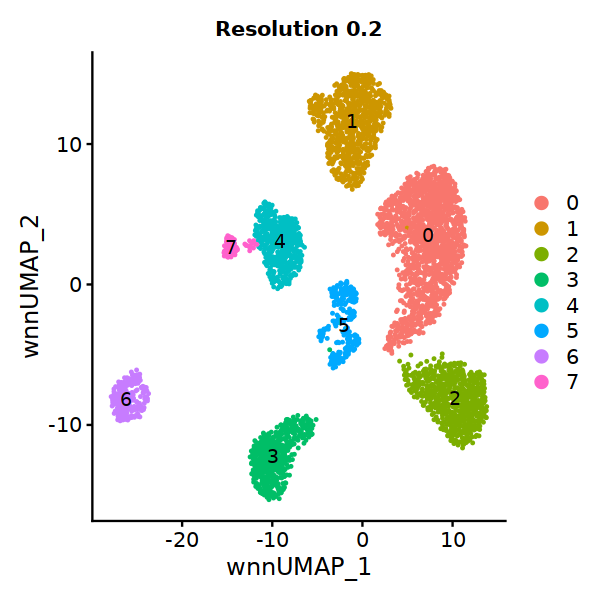

In [63]:
options(repr.plot.width = 5, repr.plot.height = 5)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T)+ ggtitle(glue::glue('Resolution 0.2')) + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))  

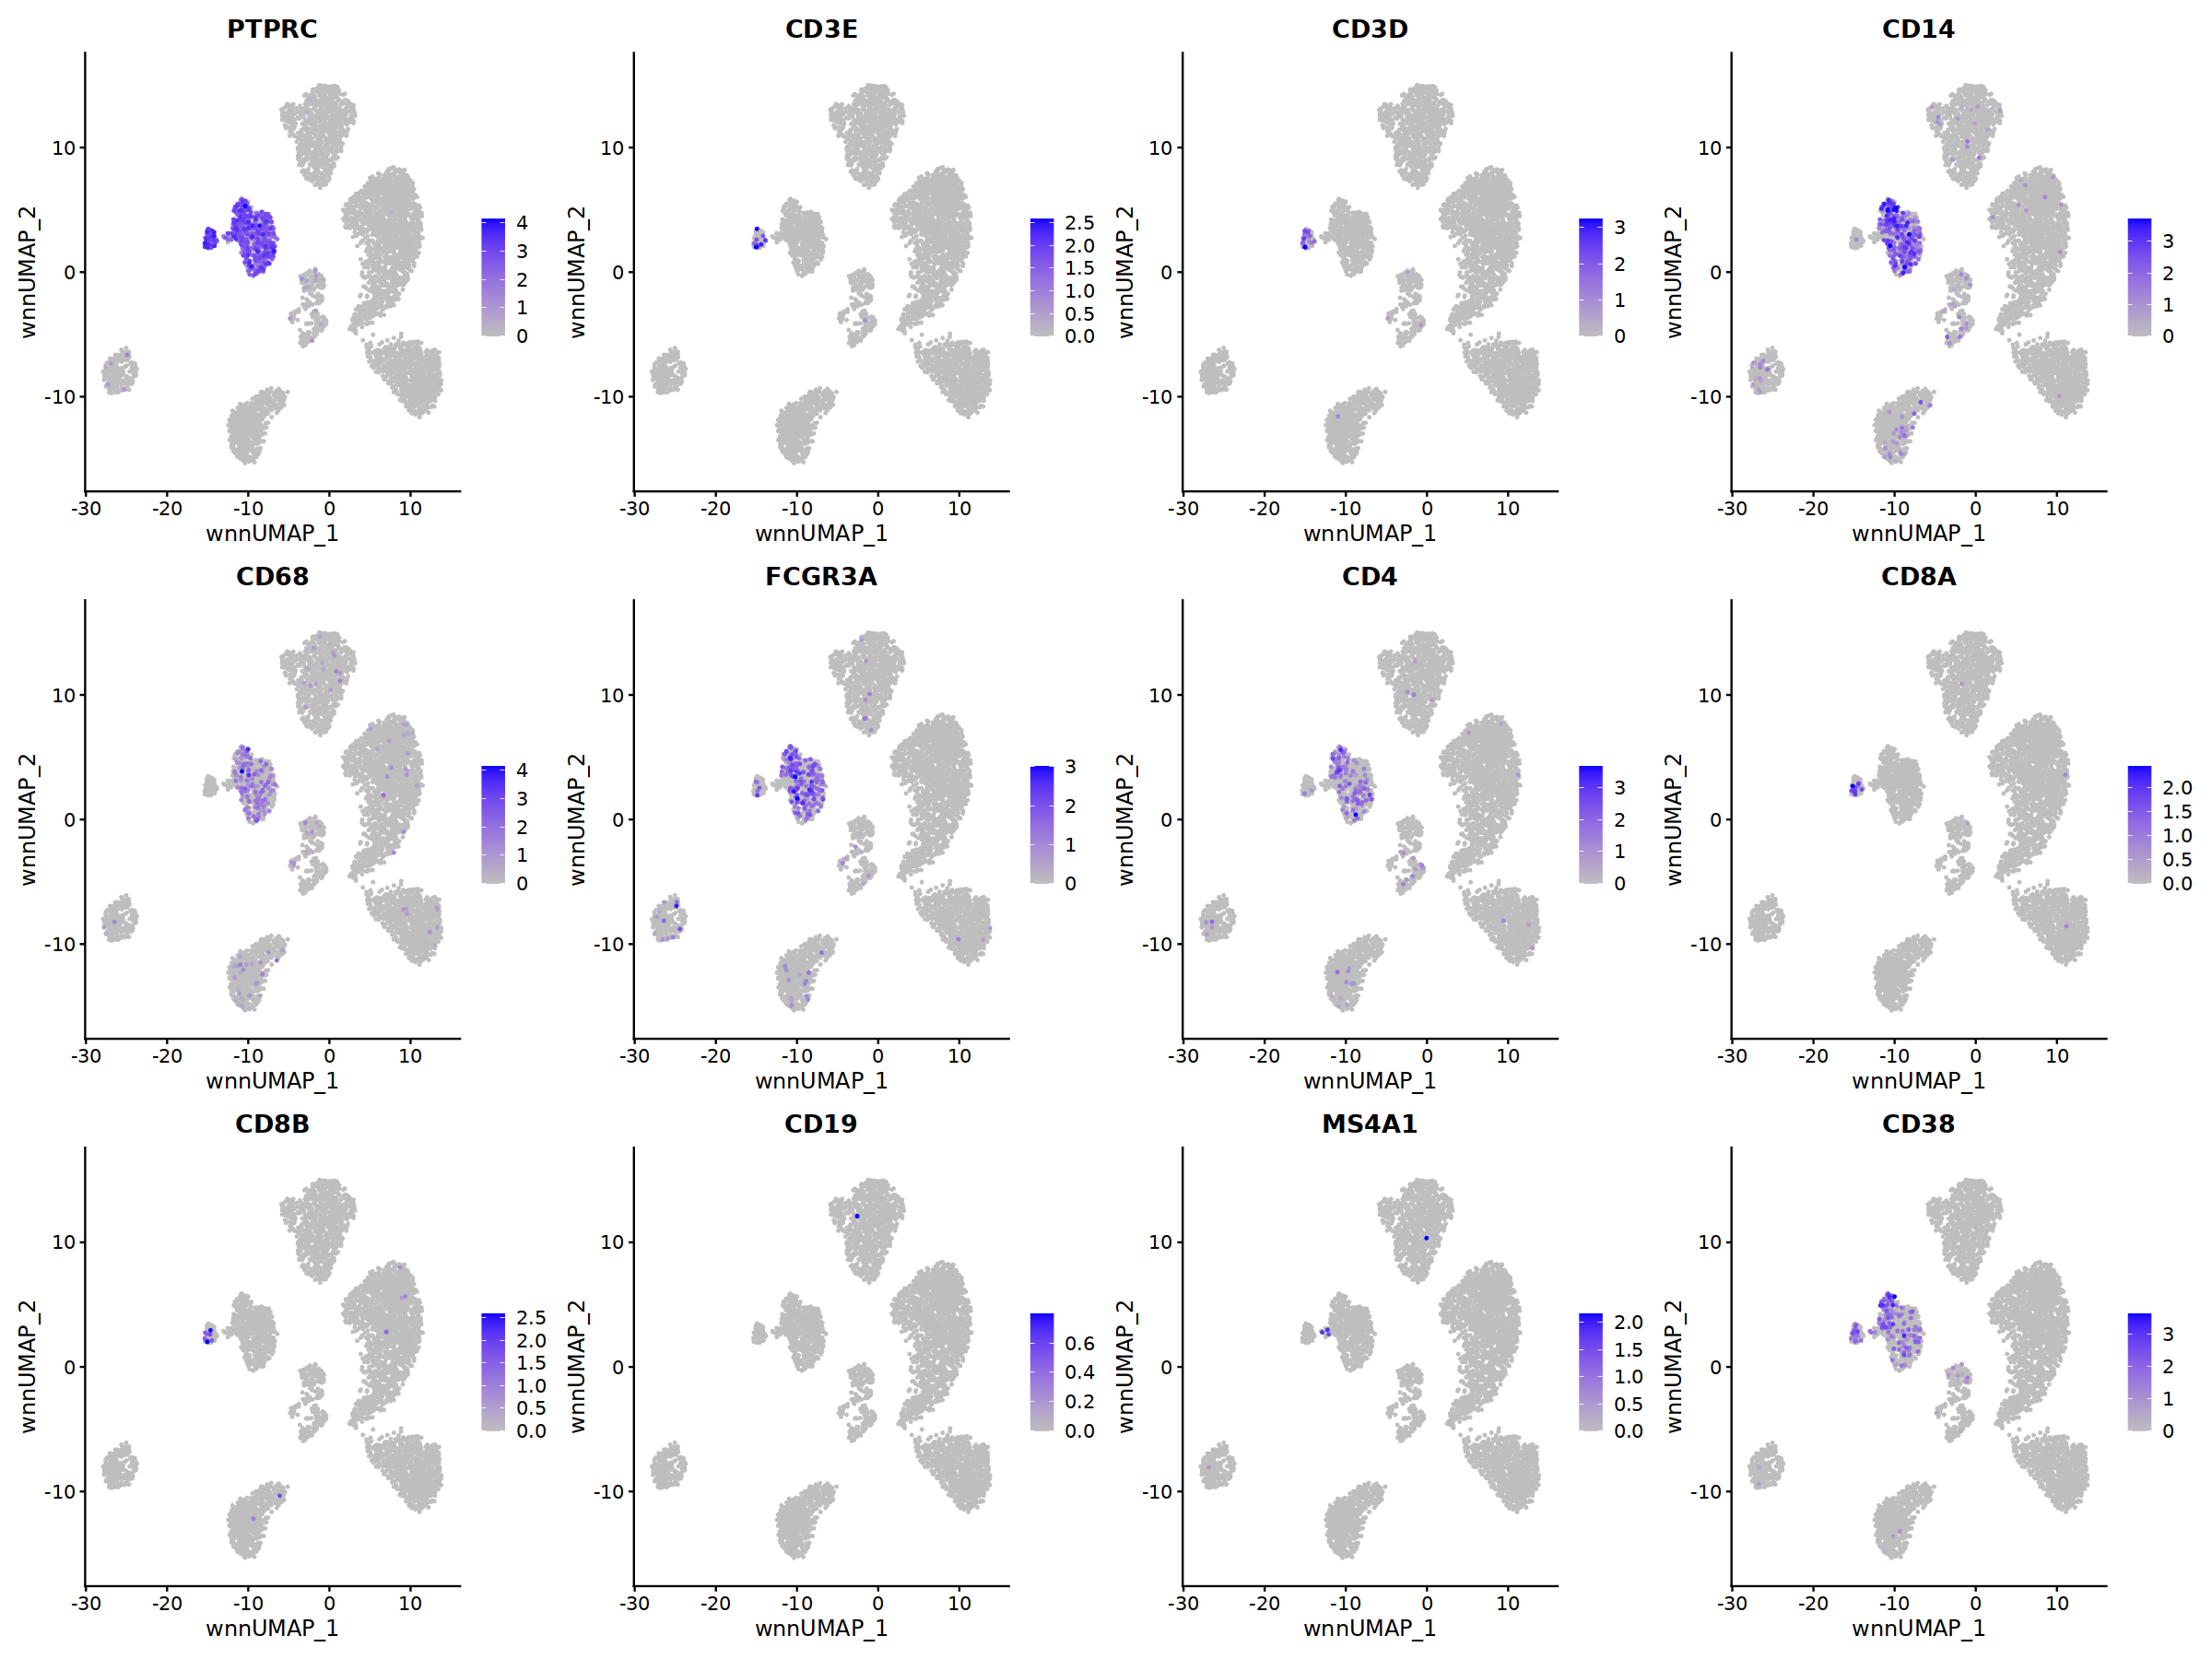

In [64]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

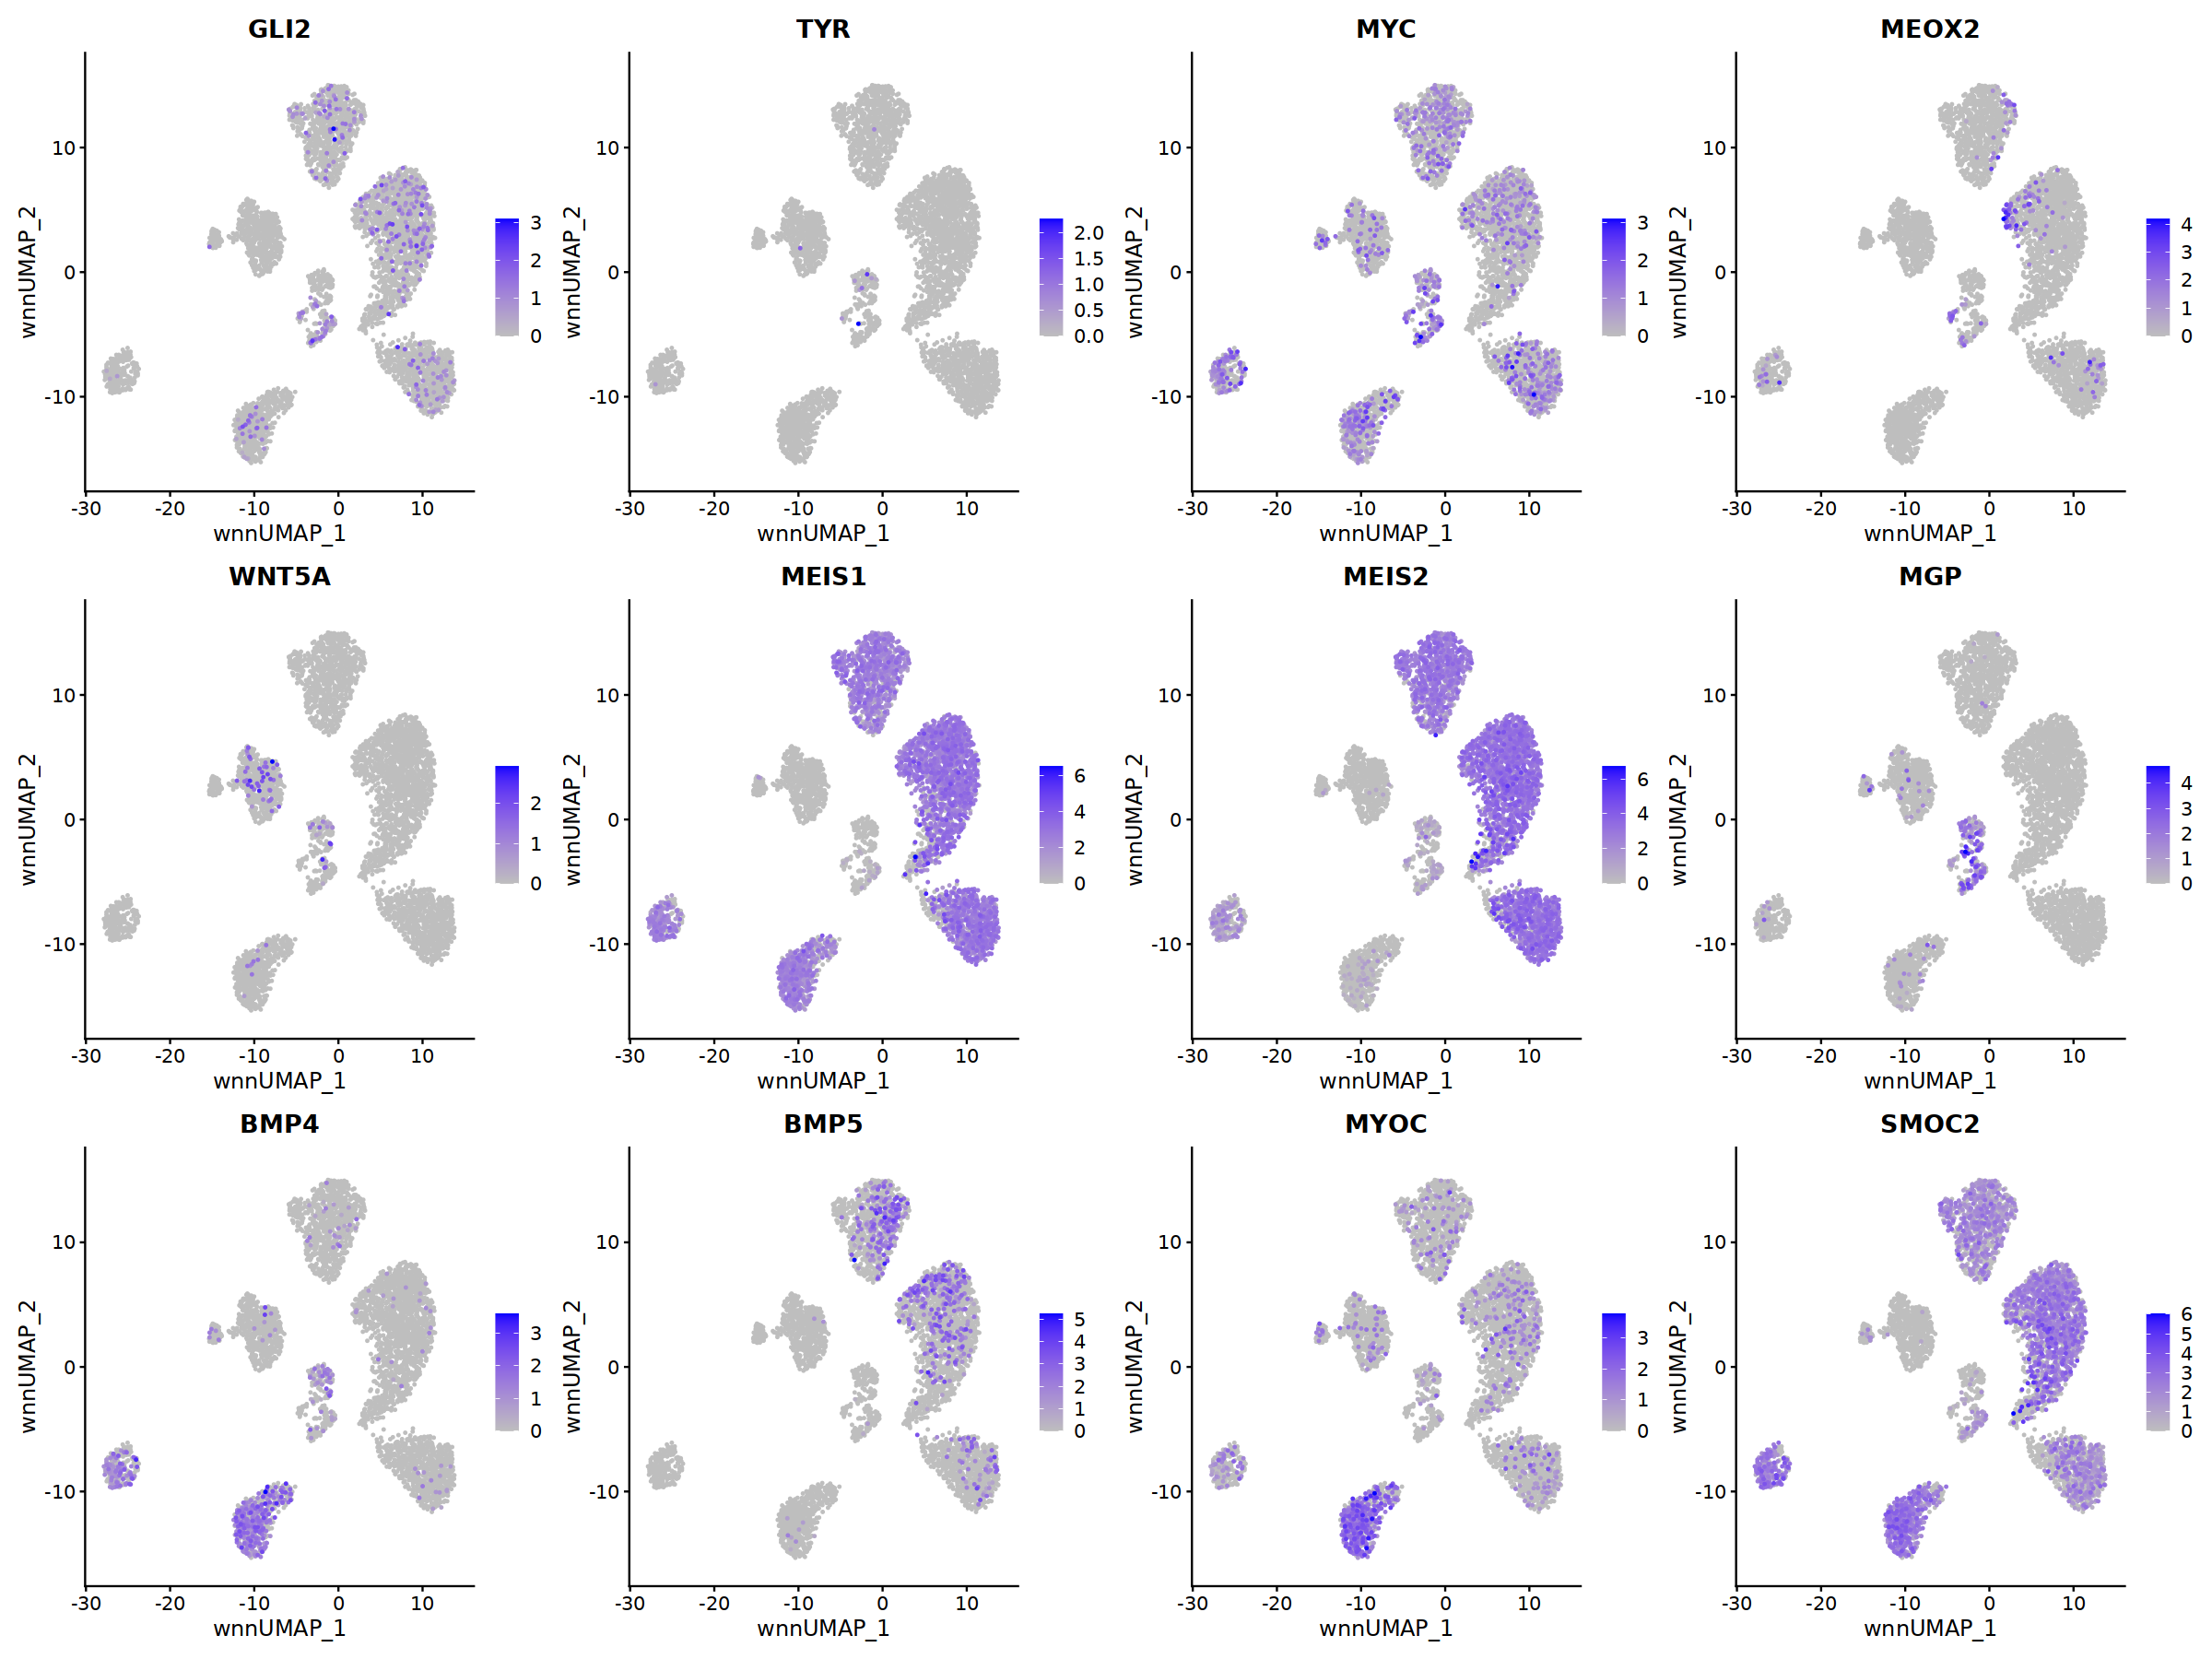

In [65]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), order=T, min.cutoff = 0)

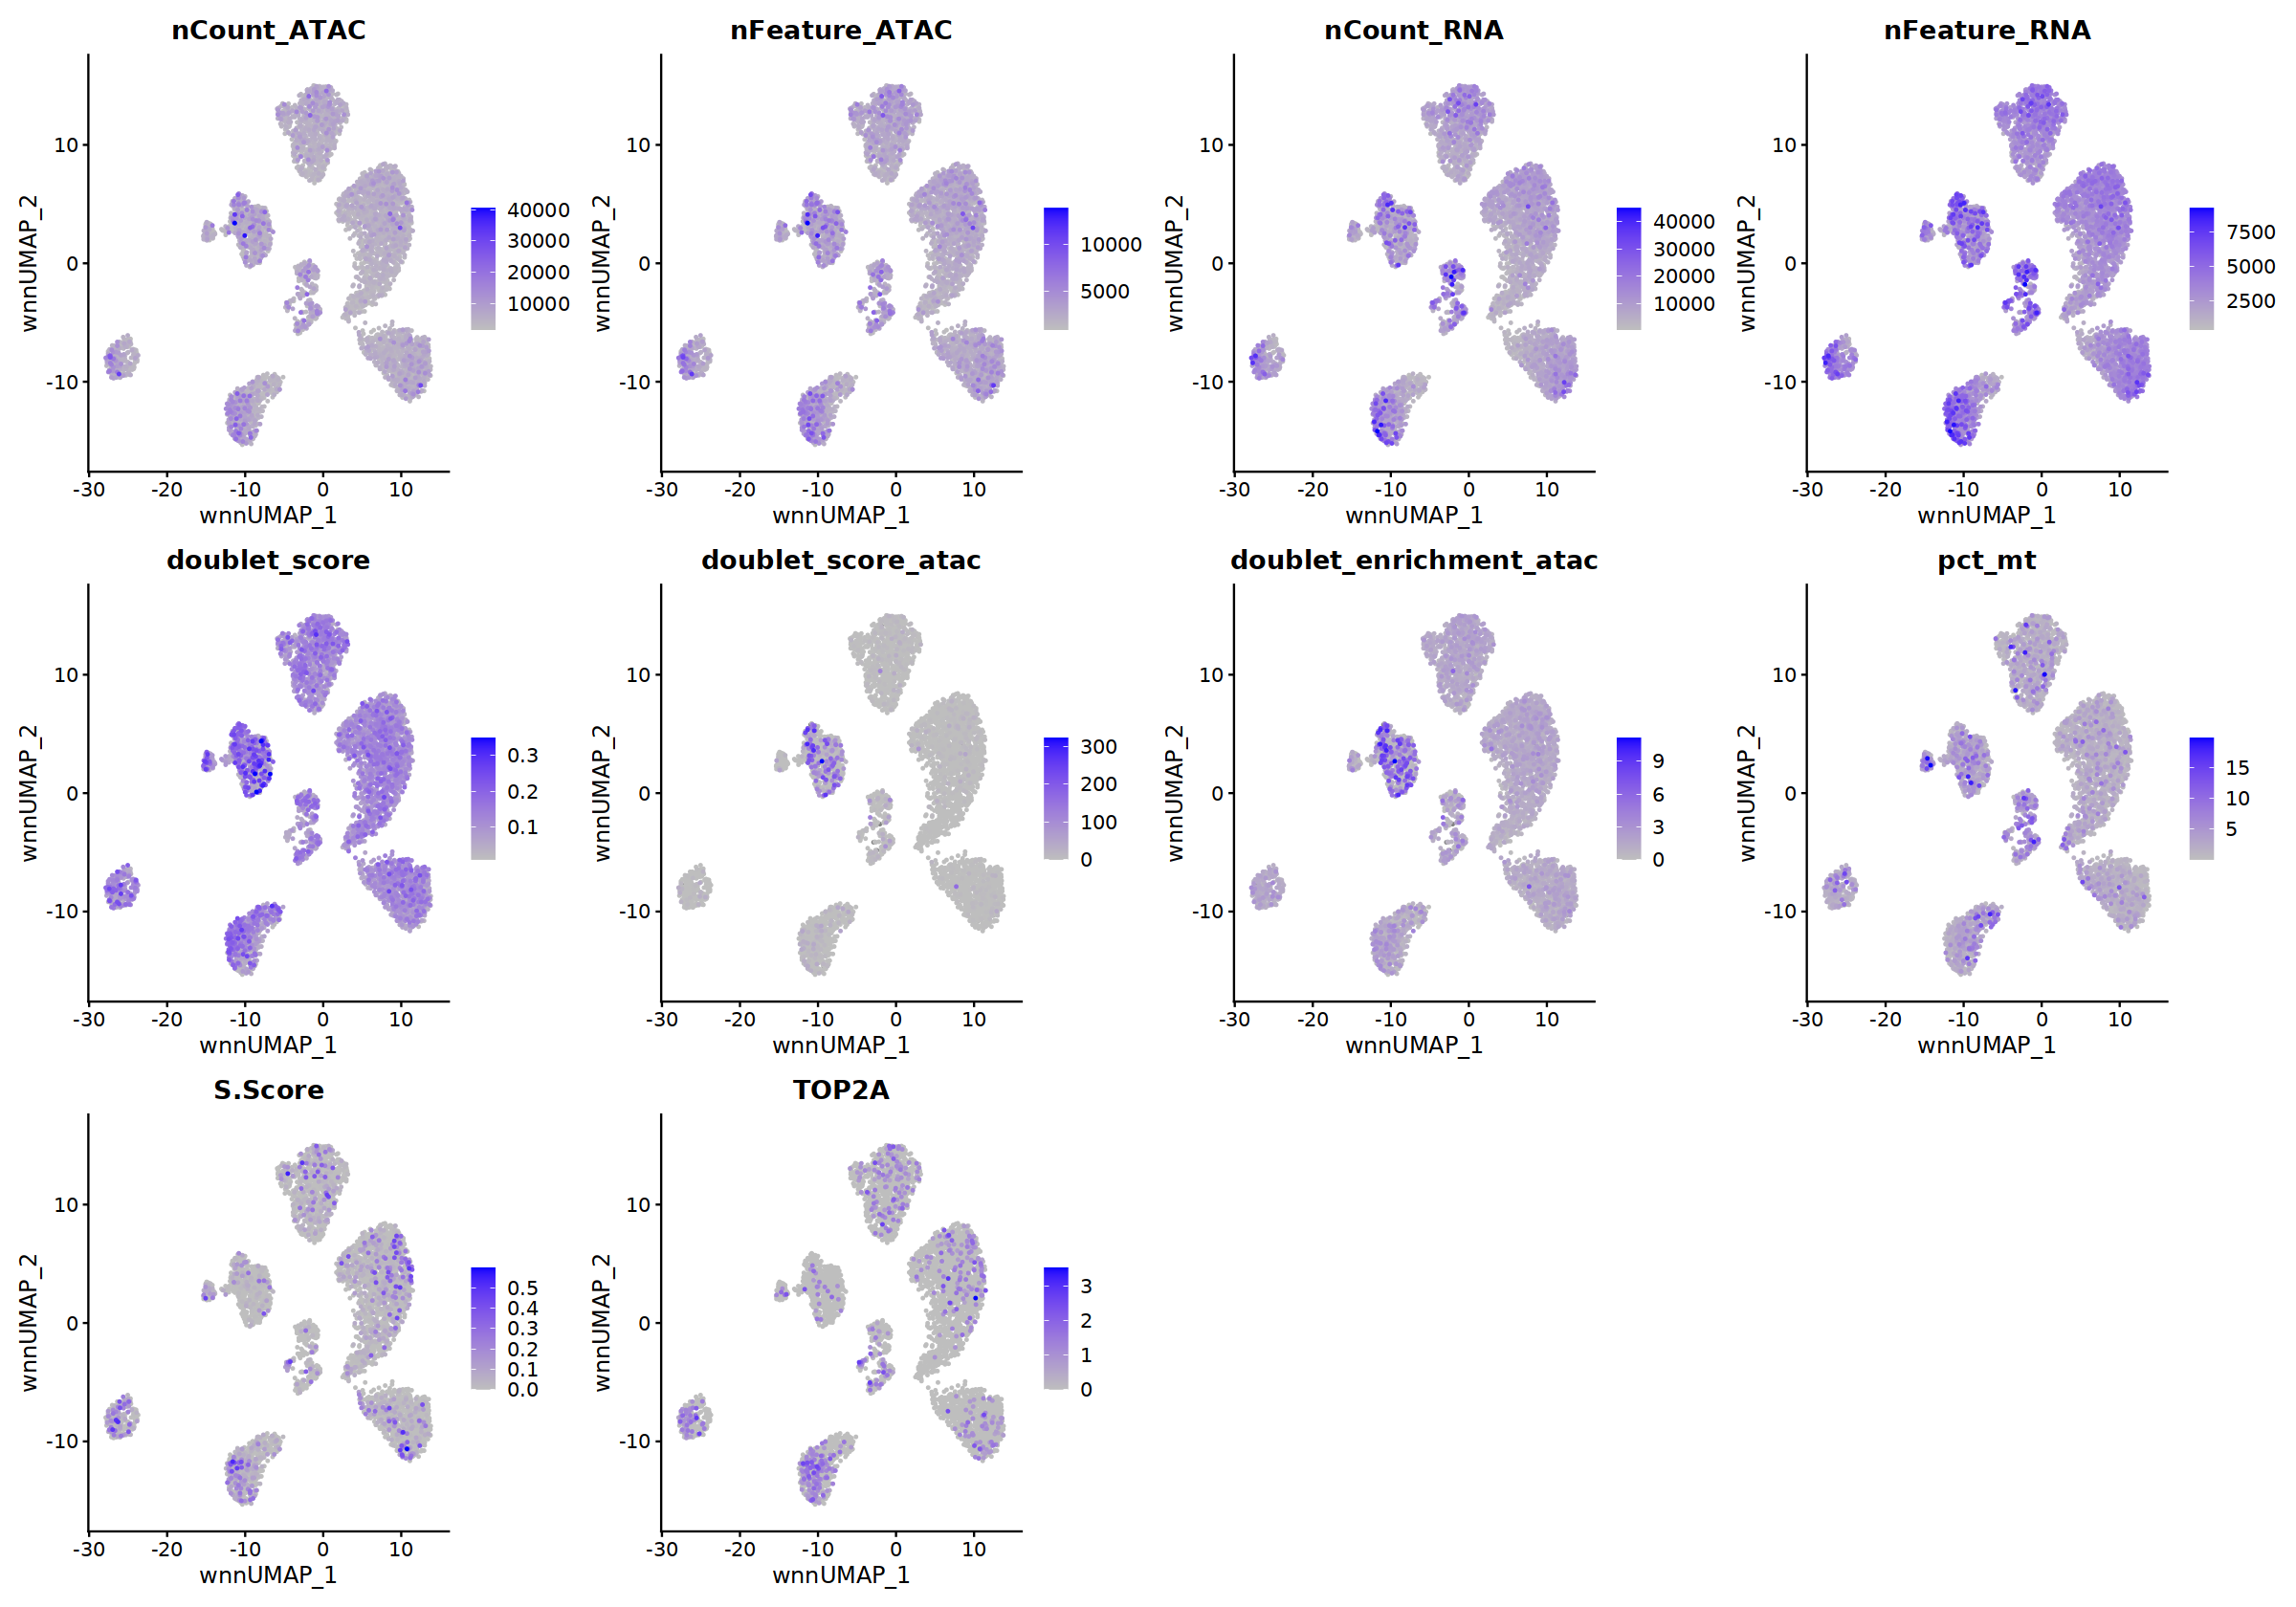

In [66]:
options(repr.plot.width = 20, repr.plot.height = 14)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt", "S.Score", "TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

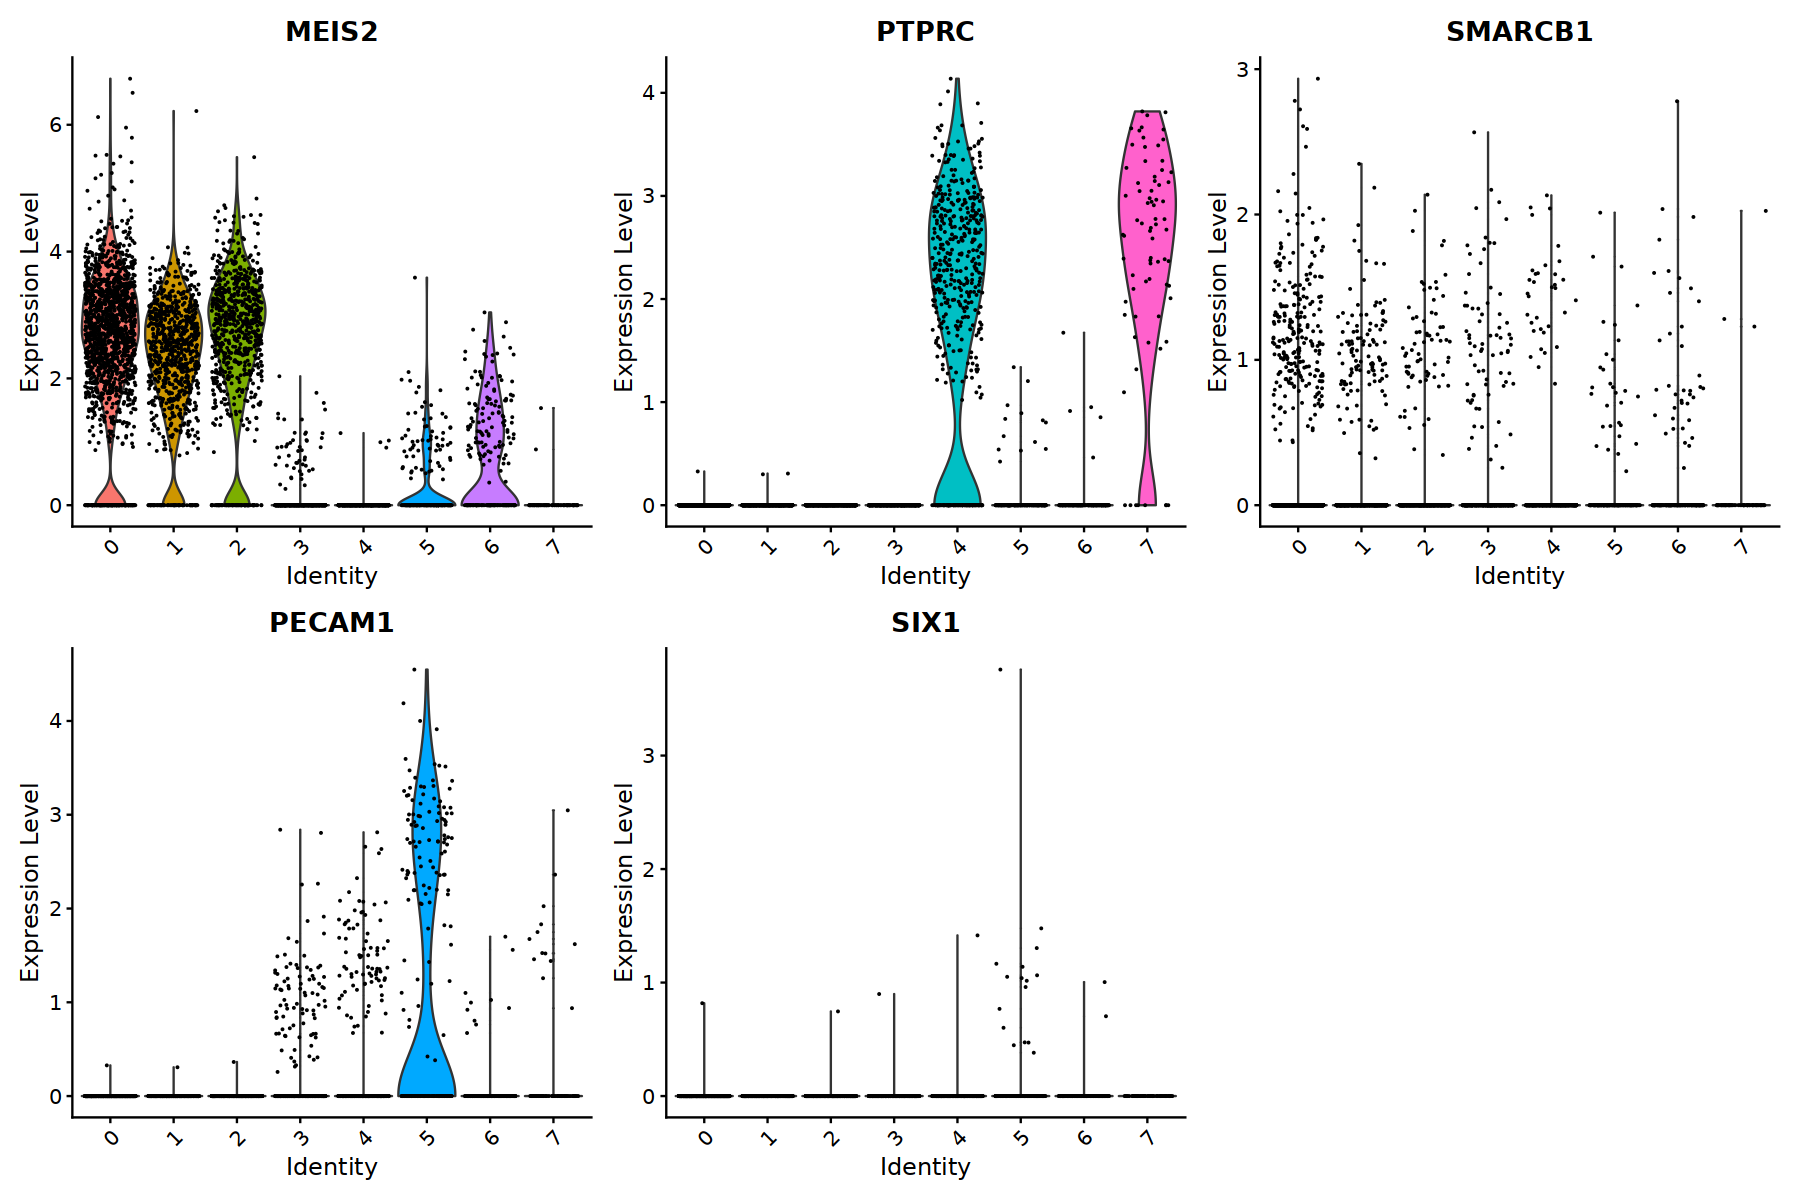

In [67]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj, features=c("MEIS2", "PTPRC","SMARCB1","PECAM1", "SIX1"),
        ncol=3)

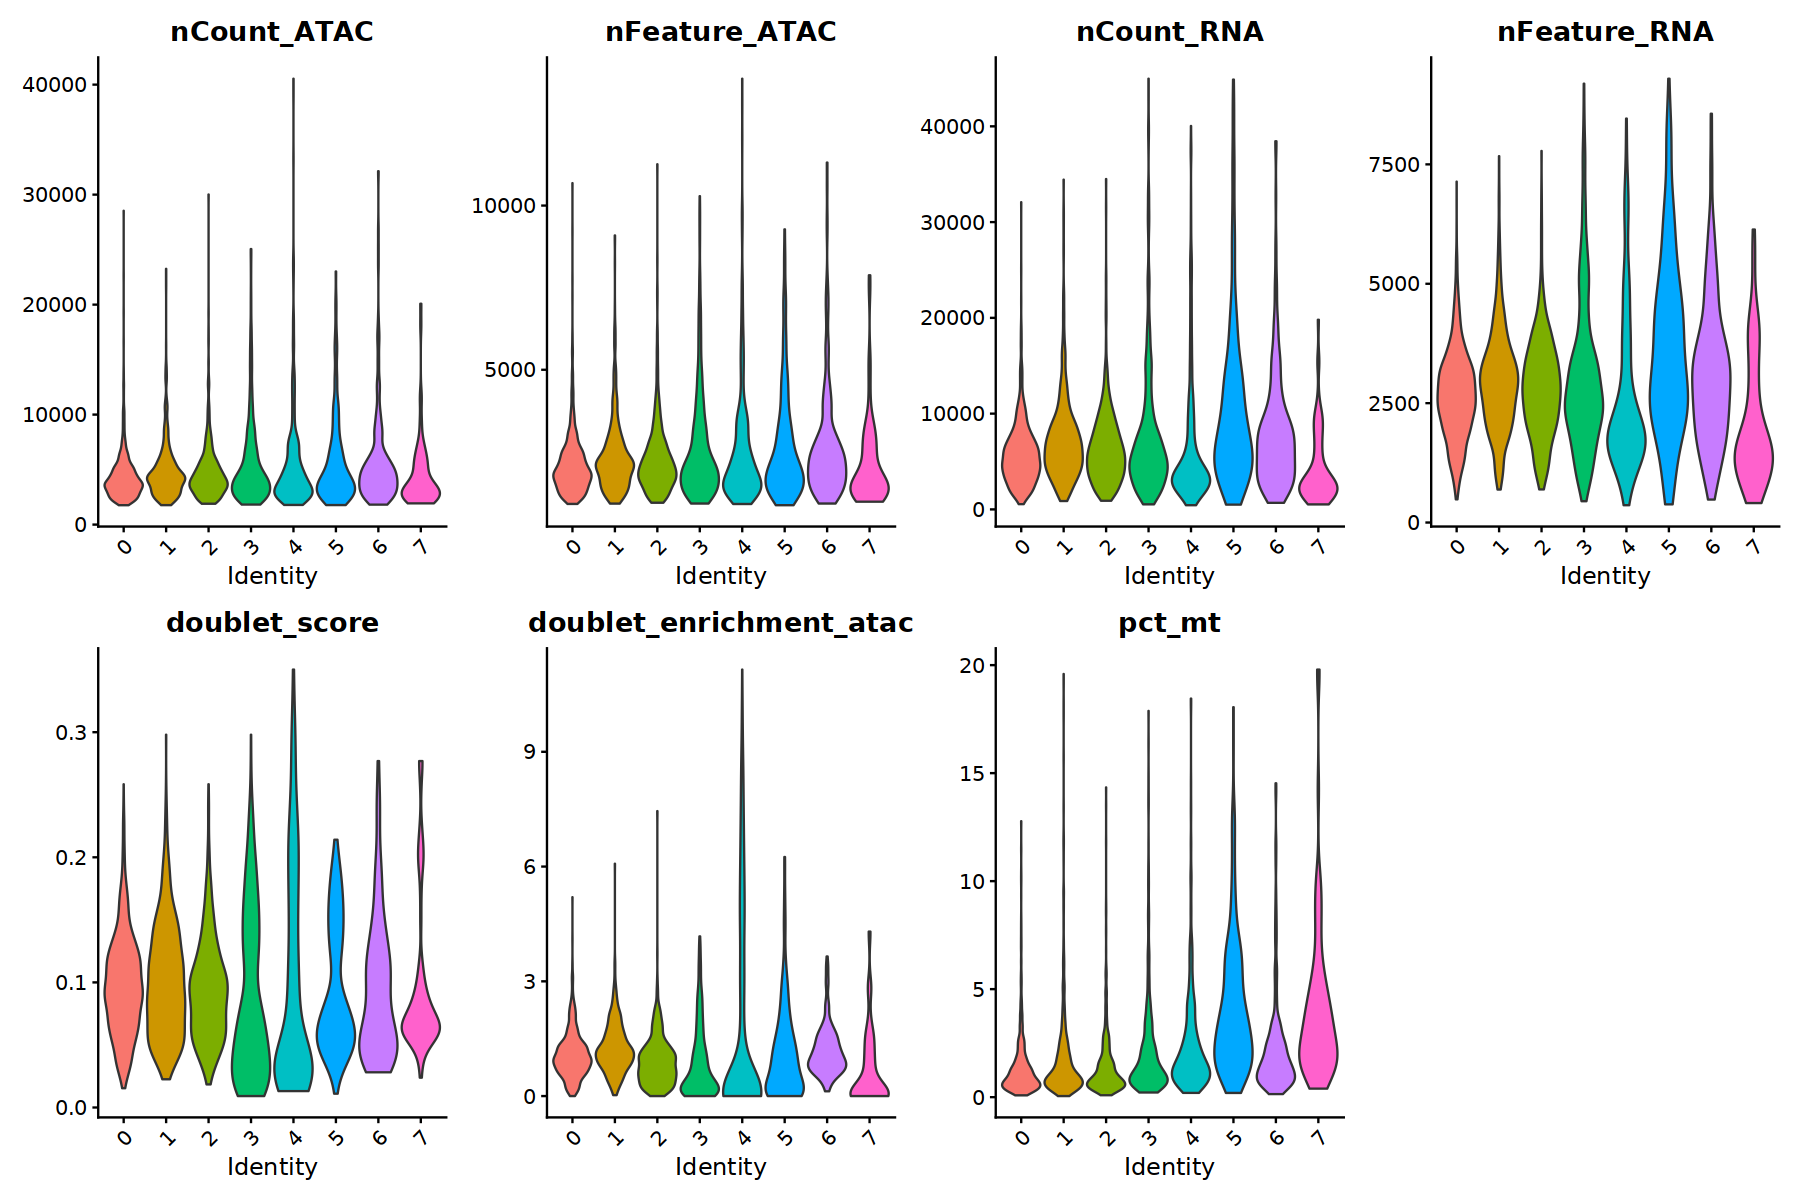

In [68]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj,features=c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score",
             "doublet_enrichment_atac", "pct_mt"), pt.size=0, ncol=4)

In [69]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



In [70]:
rna.markers %>% 
  dplyr::filter(cluster == "3") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=40)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
NCAM2,0.000000e+00,3.923504,0.700,0.031,0.000000e+00,3,NCAM2
MIR548XHG,0.000000e+00,3.866142,0.669,0.014,0.000000e+00,3,MIR548XHG
PDE7B,0.000000e+00,3.380542,0.823,0.066,0.000000e+00,3,PDE7B
CA10,0.000000e+00,3.353783,0.746,0.001,0.000000e+00,3,CA10
TNC,1.258569e-295,3.303524,0.399,0.014,3.883062e-291,3,TNC
SFMBT2,0.000000e+00,2.810398,0.852,0.114,0.000000e+00,3,SFMBT2
EYA11,0.000000e+00,2.749204,0.771,0.092,0.000000e+00,3,EYA1
RAD51B,1.109176e-136,2.621175,0.833,0.476,3.422142e-132,3,RAD51B
PTCHD1-AS,0.000000e+00,2.511068,0.462,0.003,0.000000e+00,3,PTCHD1-AS


### Rename

In [71]:
rename_clusters <- c("0"="Tumor COL26A1",
                     "1"="Tumor ELOVL5",
                     "2"="Tumor BOC",
                     "3"="Tumor NCAM",
                     "4"="Monocytes-Macrophages",
                     "5"="Endothelial cells",
                     "6"="Tumor NRG1", 
                     "7"="T-cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [72]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [73]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [74]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [75]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [76]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Immune

Calculating cluster Tumor

Calculating cluster Other stromal



In [77]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

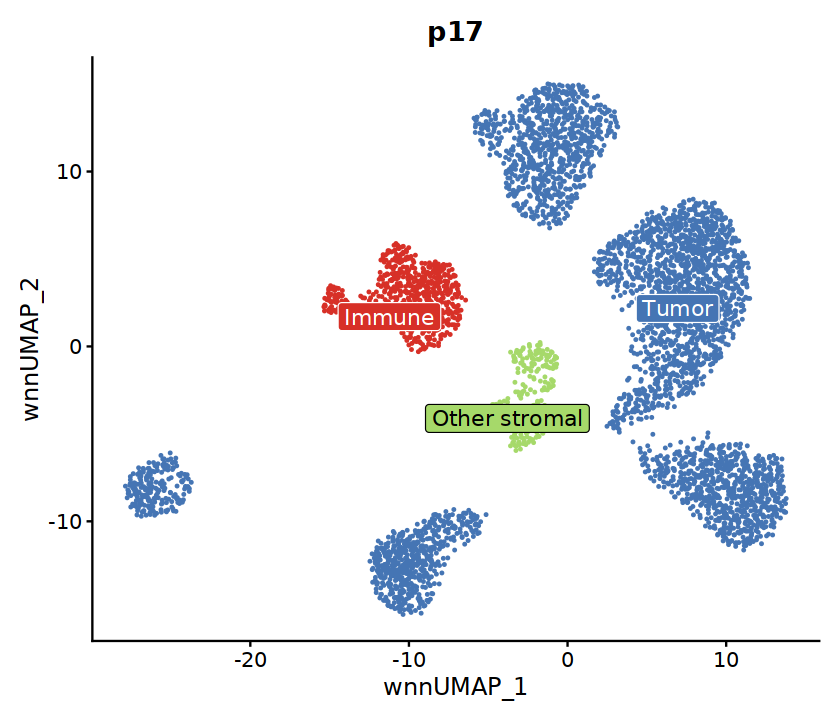

In [78]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [79]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [80]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [81]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

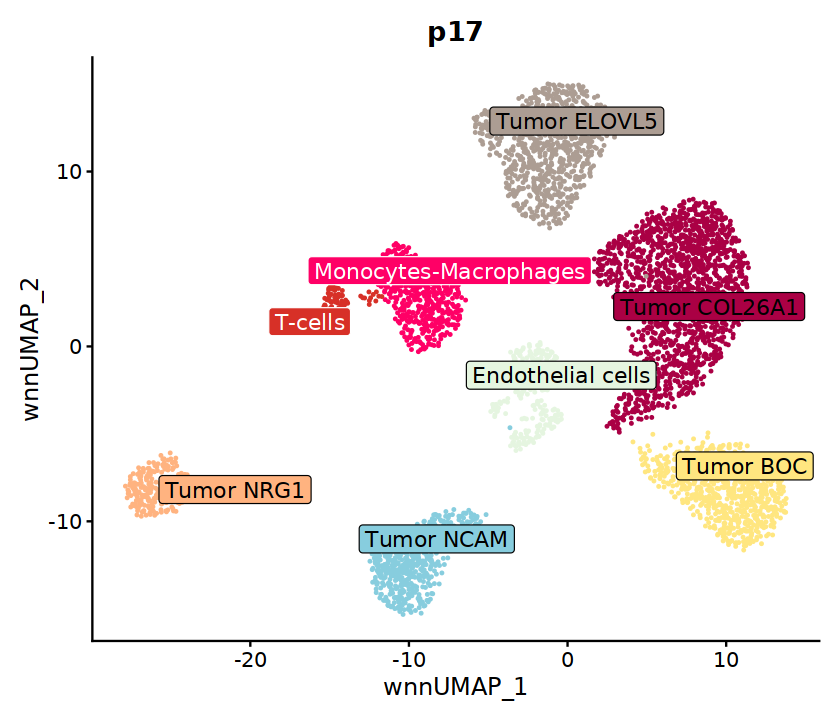

In [82]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [83]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

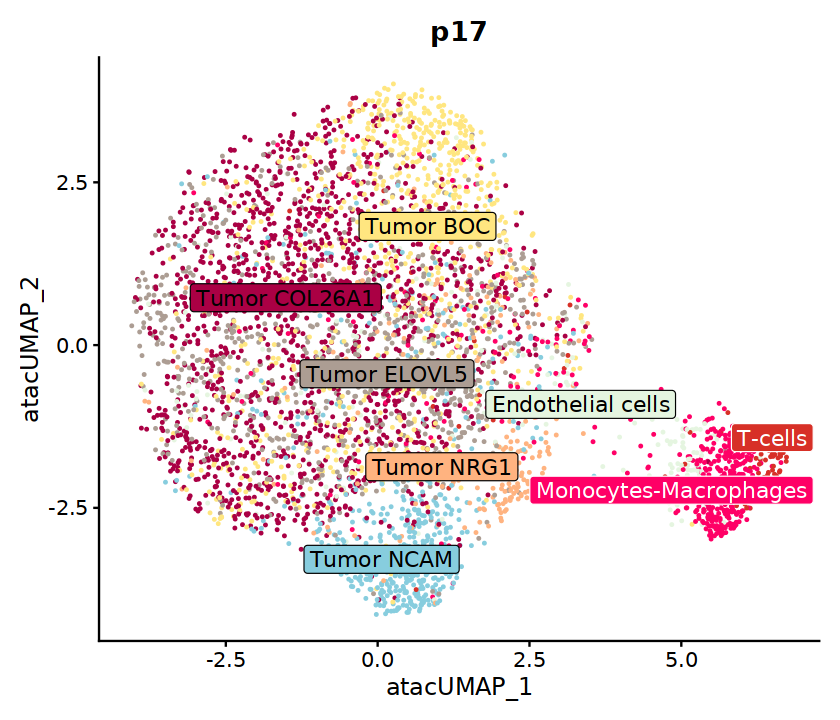

In [84]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [85]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

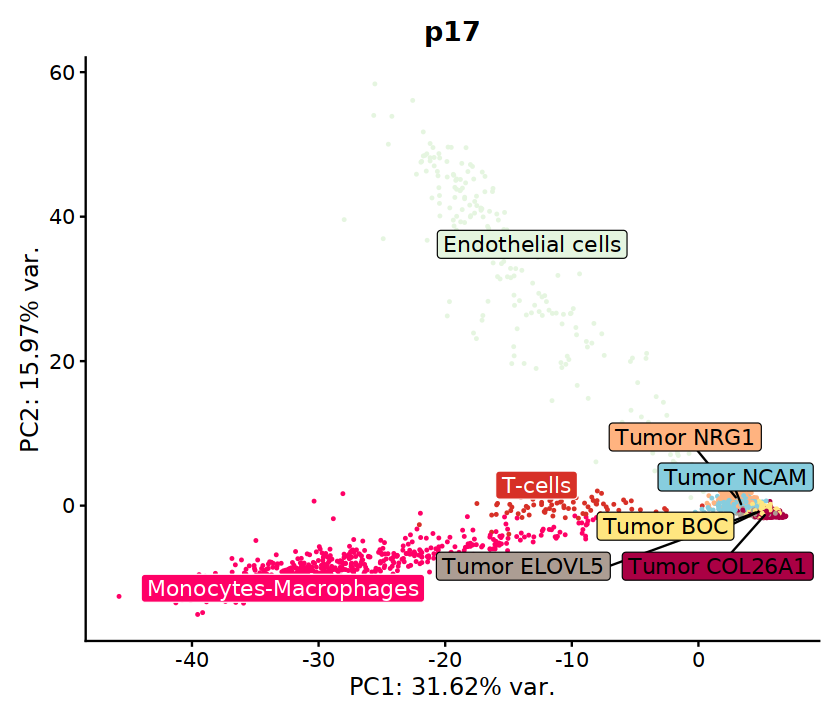

In [86]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

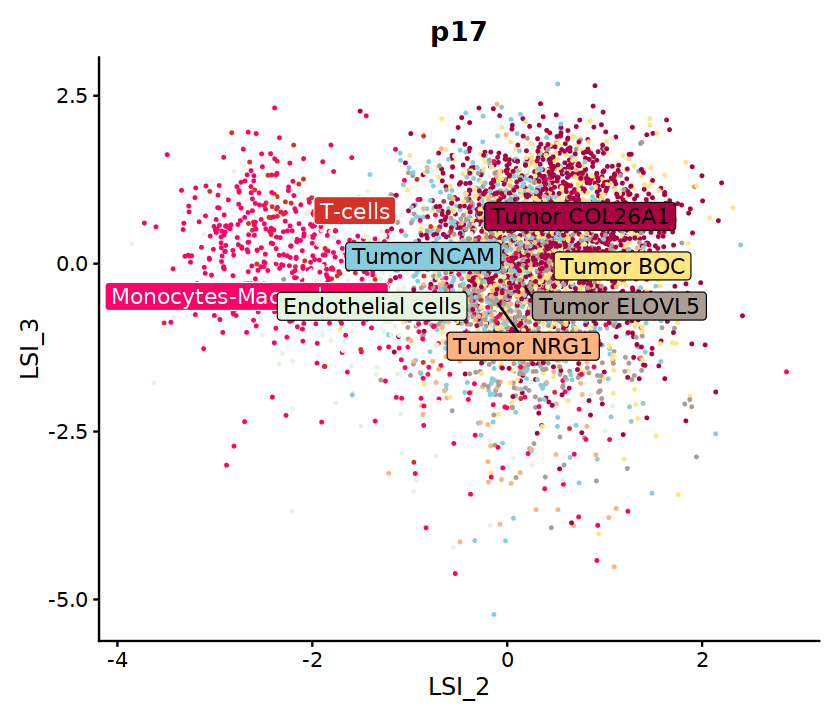

In [87]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

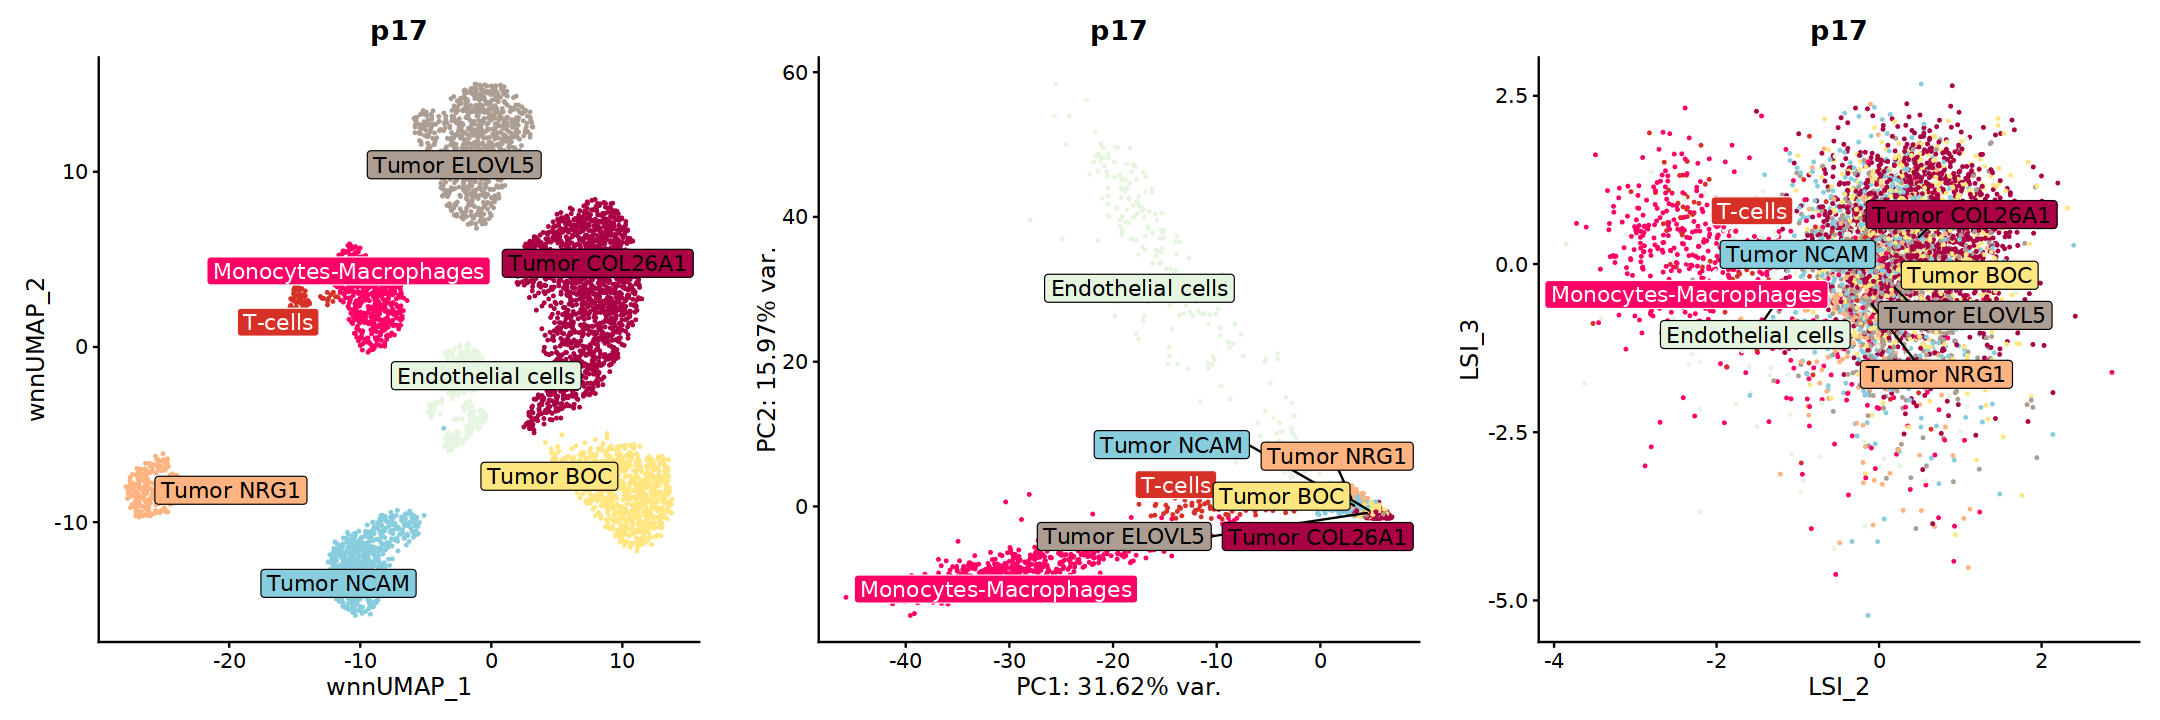

In [88]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [89]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [90]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("EYA4", "MEIS2", "FGFR2","SMOC2"), markers) ## common markers to all clusters

In [91]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

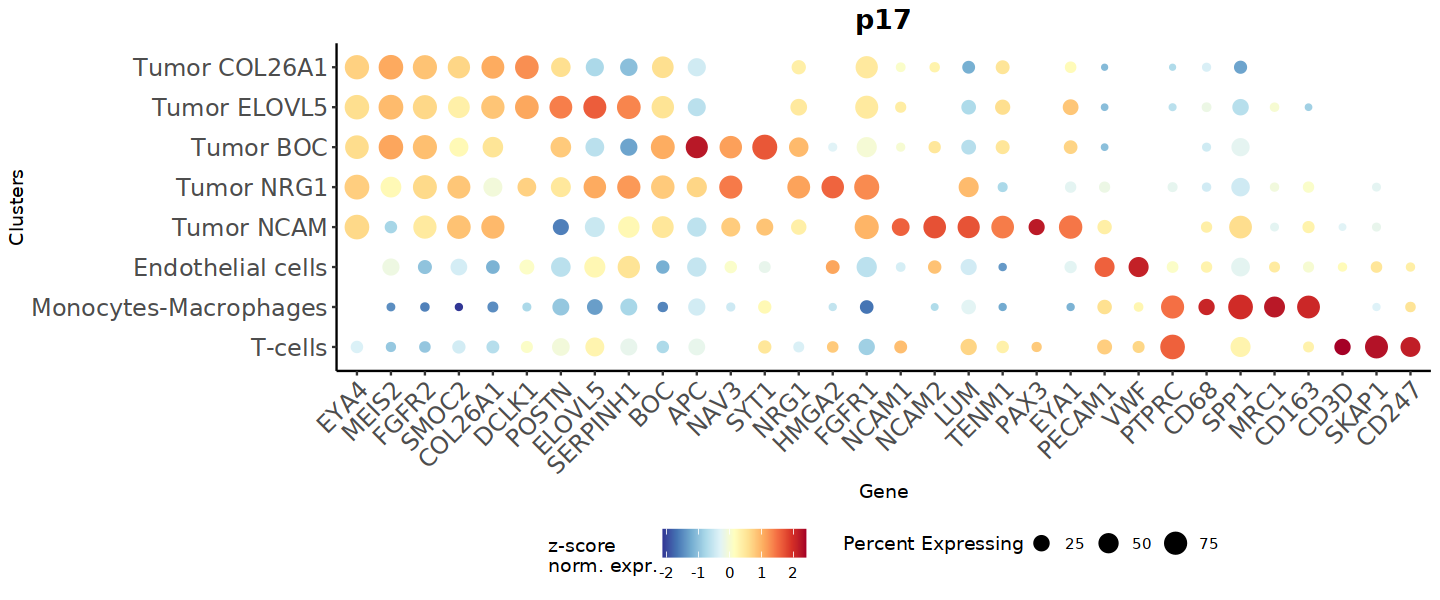

In [92]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

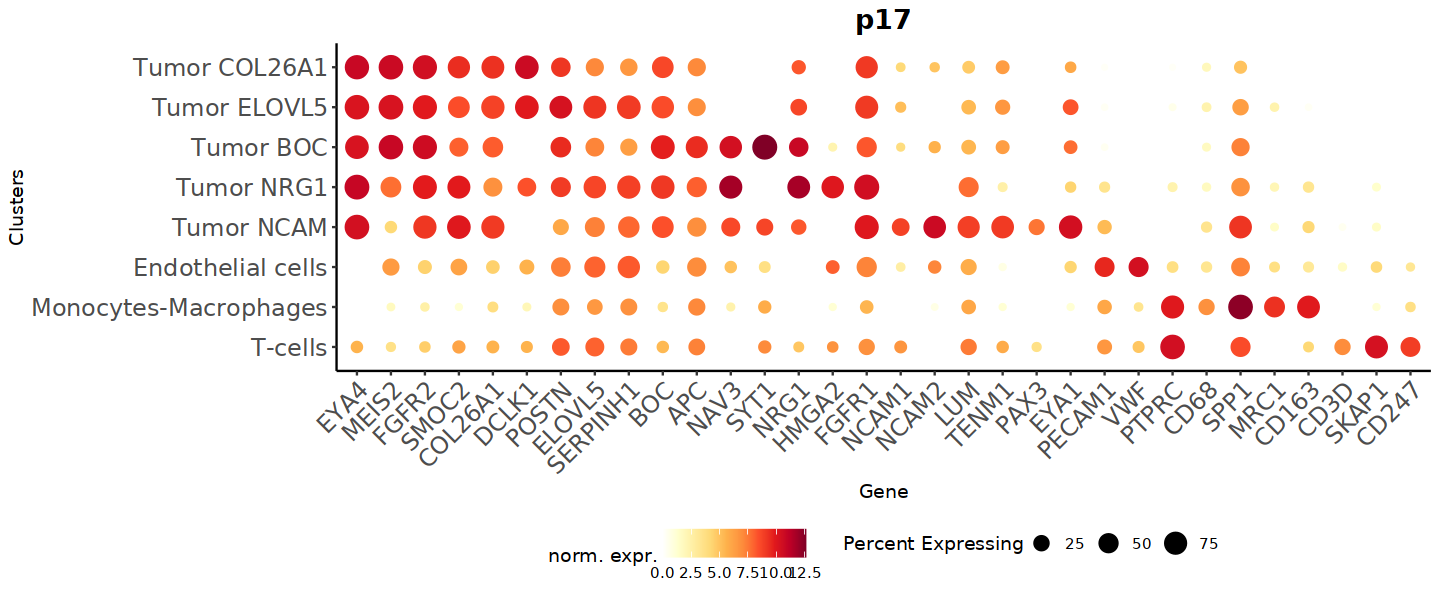

In [93]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [94]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [95]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [96]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [97]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [98]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    